# SnowPredict - Milestone 2: Data Wrangling and Project Redefinition

**Project group #8**
**Group members:** Livia Jonnatan, Jiwon Kim, Jihoon Park

**Project question (revised proposal):** For any date in the ski season (Dec 1 - Apr 30), how well can the model trained on earlier winter sessions (historical data from 2006) predict ski-condition index 30 days ahead in Canadian ski resorts? Which variables are the main driver (snow depth, fresh snowfall, rain, etc.)? Is our model better than just using the historical day-of-season average?

**Data source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api). Free, no API key.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fffad2; border-color: #ffedbb; border-width: 1px; border-radius: 3px; padding: 10px;">

**Notebook order follows:**
1. Getting the data
2. Understanding the data
3. Cleaning and preprocessing

*Conventions:* every fetch is guarded and validated before it is cached, so re-running the notebook never re-downaloads. Nothing is imputed by default.

In [1]:
import warnings

import os, json, time, glob, datetime
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib import cm, colors
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
# Silence scikit-learn's deprecation notices about the `penalty` argument
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

# 1. Getting the data

## 1.1 Resorts and representative points

Calling three elevation points (base, mid, and peak) per resort. The coordinates come from Open-Meteo's place search where it lists them. Otherwise, the resort's published coordinate is used for all three points.

In [2]:
RESORTS = {
    "Whistler Blackcomb": {"base": (50.12, -122.95, 675), "mid": (50.11, -122.95, 1480), "high":(50.06, -122.96, 2284)},
    "Big White": {"base": (49.72, -118.93, 1524), "mid": (49.72, -118.92, 1905), "high":(49.75, -118.94, 2286)},
    "Sun Peaks": {"base": (50.88, -119.91, 1186), "mid": (50.91, -119.91, 1634), "high":(50.94, -119.91, 2081)},
    "Revelstoke": {"base": (50.96, -118.16, 512), "mid": (50.96, -118.16, 1368), "high":(50.96, -118.16, 2225)},
    "Lake Louise": {"base": (51.46, -116.09, 1646), "mid": (51.46, -116.09, 2141), "high":(51.46, -116.09, 2636)},
    "Mont Tremblant": {"base": (46.21, -74.58, 230), "mid": (46.23, -74.58, 552), "high":(46.25, -74.58, 875)},
    "Mont Sainte-Anne": {"base": (47.07, -70.91, 175), "mid": (47.07, -70.91, 488), "high":(47.07, -70.91, 800)},
}

REGION = {"Whistler Blackcomb": "west", "Big White": "west", "Sun Peaks": "west", 
          "Revelstoke": "west", "Lake Louise": "west", "Mont Tremblant": "east", "Mont Sainte-Anne": "east"}
POINTS = ["base", "mid", "high"]

START_DATE = "2005-01-01"
END_DATE = "2026-05-31"

DAILY_VARS = [
    "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
    "apparent_temperature_mean", "apparent_temperature_min", "apparent_temperature_max",
    "wet_bulb_temperature_2m_mean", "wet_bulb_temperature_2m_min", "wet_bulb_temperature_2m_max",
    "dew_point_2m_mean", "relative_humidity_2m_mean", "precipitation_sum",
    "precipitation_hours", "rain_sum", "snowfall_sum", "snowfall_water_equivalent_sum",
    "sunshine_duration", "daylight_duration", "cloud_cover_mean", "shortwave_radiation_sum",
    "wind_speed_10m_max", "wind_gusts_10m_max", "surface_pressure_mean", 
    "soil_temperature_0_to_7cm_mean", "weather_code",
]
HOURLY_VARS = [
    "snowfall", "snow_depth", "temperature_2m", "wet_bulb_temperature_2m",
    "relative_humidity_2m", "dew_point_2m", "shortwave_radiation", "wind_gusts_10m",
    "wind_speed_10m", "soil_temperature_0_to_7cm", "cloud_cover", "weather_code",
    "surface_pressure", "precipitation", "rain", "apparent_temperature",
]
MODEL = "best_match"

In [3]:
HEADERS = {"User-Agent": "AC209A-SnowPredict (Harvard AC209A Fall 2026 project)"}
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
RAW_DIR = "data/raw"

os.makedirs(RAW_DIR, exist_ok=True)

def slug(name):
    return name.replace(" ", "_").replace("-", "_").replace(".", "")

def raw_path(name, point, year):
    return f"{RAW_DIR}/{slug(name)}_{point}_{year}.json"

## 1.2 API call - guarded, validated, cached

One request per resort, point, and calendar year. The guard fetches only if the file is not already on disk. The validation resufes to cache a bad or partial response, so a cached file can be trusted. 429 and 5xx are retried with backoff and any other 4xx raises.

In [4]:
def validate_payload(j, start, end):
    """Check if the JSON is a complete archive response for [start, end]"""
    if "error" in j:
        raise ValueError(f"API error: {j.get("reason")}")
    for key in ("daily", "hourly"):
        if key not in j or "time" not in j[key]:
            raise ValueError(f"response has no '{key}' block")
    n_days = (pd.Timestamp(end)-pd.Timestamp(start)).days + 1
    if len(j["daily"]["time"]) != n_days:
        raise ValueError(f"expected {n_days} daily rows, got {len(j["daily"]["time"])}")
    if len(j["hourly"]["time"]) != 24 * n_days:
        raise ValueError(f"expected {24*n_days} hourly rows, got {len(j["hourly"]["time"])}")
    missing_d = [v for v in DAILY_VARS if v not in j["daily"]]
    missing_h = [v for v in HOURLY_VARS if v not in j["hourly"]]
    if missing_d or missing_h:
        raise ValueError(f"missing daily {missing_d} / hourly {missing_h}")

def fetch_year(name, point, lat, lon, elev, year, retries=6):
    path = raw_path(name, point, year)
    if os.path.isfile(path):
        return path, "cached"
    s = max(pd.Timestamp(f"{year}-01-01"), pd.Timestamp(START_DATE)).strftime("%Y-%m-%d")
    e = min(pd.Timestamp(f"{year}-12-31"), pd.Timestamp(END_DATE)).strftime("%Y-%m-%d")
    params = {"latitude": lat, "longitude": lon, "elevation": elev, "start_date": s, "end_date": e,
              "daily": ",".join(DAILY_VARS), "hourly":",".join(HOURLY_VARS), "models": MODEL, "timezone": "auto"}
    r = None
    for attempt in range(retries):
        r =requests.get(ARCHIVE_URL, params=params, headers=HEADERS, timeout=120)
        if r.status_code == 429:
            wait = 60*(attempt+1)
            print(f" 429 on {name}/{point}/{year}; waiting {wait}s")
            time.sleep(wait); continue
        if r.status_code in (500, 502, 503, 504):
            time.sleep(10 * (attempt+1)); continue
        r.raise_for_status()
        r.encoding = "UTF-8"
        try:
            j = r.json()
            validate_payload(j, s, e)
        except (ValueError, KeyError) as err:            # not JSON, or incomplete JSON
            last = f"bad body ({type(err).__name__})"
            print(f"{last} on {name}/{point}/{year}; retrying in {30*(attempt+1)}s")
            time.sleep(30 * (attempt + 1)); continue
        with open(path, "w") as f:
            f.write(r.text)
        return path, "fetched"
    print(f"  SKIPPED {name}/{point}/{year}: last status {r.status_code}")
    return path, "failed"

In [5]:
years = range(int(START_DATE[:4]), int(END_DATE[:4]) + 1)
n_total = len(RESORTS) * len(POINTS) * len(years)
manifest, consecutive_fail = [], 0
counts = {"fetched": 0, "cached": 0, "failed": 0}

for name, pts in RESORTS.items():
    for point in POINTS:
        lat, lon, elev = pts[point]
        for y in years:
            path, status = fetch_year(name, point, lat, lon, elev, y)
            counts[status] += 1
            ok = status != "failed"
            manifest.append({"resort": name, "point": point, "year": y, "path": path,
                             "status": status, "bytes": os.path.getsize(path) if status != "failed" else 0, 
                             "cached_on": datetime.date.fromtimestamp(os.path.getmtime(path)) if status != "failed" else None})
            if status == "fetched":
                consecutive_fail = 0
                time.sleep(2)
            elif status == "failed":
                consecutive_fail += 1
                if consecutive_fail >= 5:
                    print(" 5 failures in a row; pausing 10 minutes before continuing")
                    time.sleep(10 * 60); consecutive_fail = 0
        done = sum(counts.values())
        print(f"[{done:3d}/{n_total}] {name}/{point}: fetched {counts["fetched"]}, cached {counts["cached"]}, failed {counts["failed"]}")

manifest = pd.DataFrame(manifest)
manifest.to_csv("data/raw_manifest.csv", index=False)
print()
print(f"Done. {counts["fetched"]} fetched this run, {counts["cached"]} already cached, {counts["failed"]} failed and still needed.")
print("Raw JSON on disk: %.1f MB across %d files" % (manifest["bytes"].sum() / 1e6, (manifest["status"] != "failed").sum()))
if (manifest["status"] == "failed").any():
    print("Re-run this cell later to fetch the failed files:")
    display(manifest.loc[manifest["status"] == "failed", ["resort", "point", "year"]])
manifest.head()

[ 22/462] Whistler Blackcomb/base: fetched 0, cached 22, failed 0
[ 44/462] Whistler Blackcomb/mid: fetched 0, cached 44, failed 0
[ 66/462] Whistler Blackcomb/high: fetched 0, cached 66, failed 0
[ 88/462] Big White/base: fetched 0, cached 88, failed 0
[110/462] Big White/mid: fetched 0, cached 110, failed 0
[132/462] Big White/high: fetched 0, cached 132, failed 0
[154/462] Sun Peaks/base: fetched 0, cached 154, failed 0
[176/462] Sun Peaks/mid: fetched 0, cached 176, failed 0
[198/462] Sun Peaks/high: fetched 0, cached 198, failed 0
[220/462] Revelstoke/base: fetched 0, cached 220, failed 0
[242/462] Revelstoke/mid: fetched 0, cached 242, failed 0
[264/462] Revelstoke/high: fetched 0, cached 264, failed 0
[286/462] Lake Louise/base: fetched 0, cached 286, failed 0
[308/462] Lake Louise/mid: fetched 0, cached 308, failed 0
[330/462] Lake Louise/high: fetched 0, cached 330, failed 0
[352/462] Mont Tremblant/base: fetched 0, cached 352, failed 0
[374/462] Mont Tremblant/mid: fetched 0,

,resort,point,year,path,status,bytes,cached_on
0,Whistler Blackcomb,base,2005,data/raw/Whistler_Blackcomb_base_2005.json,cached,838986,2026-10-31
1,Whistler Blackcomb,base,2006,data/raw/Whistler_Blackcomb_base_2006.json,cached,840744,2026-10-31
2,Whistler Blackcomb,base,2007,data/raw/Whistler_Blackcomb_base_2007.json,cached,838811,2026-10-31
3,Whistler Blackcomb,base,2008,data/raw/Whistler_Blackcomb_base_2008.json,cached,843344,2026-10-31
4,Whistler Blackcomb,base,2009,data/raw/Whistler_Blackcomb_base_2009.json,cached,843356,2026-10-31


## 1.3 Parse into one table

Hourly data are first concatenated across years for each resort-point. Then, aggregated into three local-time dayparts:

| Daypart | Hours (local) | Attached to |
| ----- | ----- | ----- |
| `night` | 18:00 previous day - 07:59 | The following date (it sets that morning's surface) |
| `am` | 08:00 - 11:59 | same date |
| `pm` | 12:00 - 17:59 | same date |

The parse produce three tables, each derived from the previous one. So, a different daypart definition later needs no re-parsing of the JSON.

| File | One row = | Purpose |
| ----- | ----- | ----- |
| `data/weather_hourly_long.parquet` | resort, point, hour (+ daypart label) | hourly aggregate, re-aggregate later |
| `data/weather_daypart_long.parquet` | resort, point, date, daypart | daypart-level |
| `data/weather_daily_wide.csv` | resort, point, date | daily block + daypart summaries as columns |

Each daypart summary is merged onto the daily block with `validate="one-to-one"` and a row-count assert.

In [6]:
DAYPART_AGG = {
    "temp_mean":       ("temperature_2m", "mean"),
    "temp_min":        ("temperature_2m", "min"),
    "temp_max":        ("temperature_2m", "max"),
    "hours_above_0c":  ("temperature_2m", lambda s: (s > 0).sum()),
    "feels_mean":      ("apparent_temperature", "mean"),
    "wetbulb_mean":    ("wet_bulb_temperature_2m", "mean"),
    "wetbulb_max":     ("wet_bulb_temperature_2m", "max"),
    "rh_mean":         ("relative_humidity_2m", "mean"),
    "dewpoint_mean":   ("dew_point_2m", "mean"),
    "radiation_mean":  ("shortwave_radiation", "mean"),
    "wind_mean":       ("wind_speed_10m", "mean"),
    "gust_max":        ("wind_gusts_10m", "max"),
    "soil_temp_mean":  ("soil_temperature_0_to_7cm", "mean"),
    "cloud_mean":      ("cloud_cover", "mean"),
    "weather_code_max":("weather_code", "max"),            # most severe code in the block
    "pressure_mean":   ("surface_pressure", "mean"),
    "precip_sum":      ("precipitation", "sum"),
    "rain_sum":        ("rain", "sum"),
    "snowfall_sum":    ("snowfall", "sum"),
    "snow_depth_mean": ("snow_depth", "mean"),
    "snow_depth_max":  ("snow_depth", "max"),
    "n_hours":         ("temperature_2m", "size"),         # hours in the block (6/4/14 expected)
}

In [7]:
def load_point(name, point):
    """All years of one resort-point -> dailly dataframe, hourly dataframe, api elevation"""
    paths = manifest.loc[(manifest["resort"] == name) & (manifest["point"] == point), "path"]
    dailies, hourlies, elev = [], [], None
    for p in sorted(paths):
        with open(p) as f:
            j = json.load(f)
        dailies.append(pd.DataFrame(j["daily"]))
        hourlies.append(pd.DataFrame(j["hourly"]))
        elev = j.get("elevation", elev)
    daily = pd.concat(dailies, ignore_index=True).rename(columns={"time": "date"})
    daily["date"] = pd.to_datetime(daily["date"])
    hourly = pd.concat(hourlies, ignore_index=True)
    hourly["time"] = pd.to_datetime(hourly["time"])
    return daily, hourly, elev

In [8]:
def label_dayparts(hourly):
    # daypart label and the ski-day date each hour belongs to (18:00-23:59 -> next day's night)
    hour = hourly["time"].dt.hour
    return hourly.assign(
        daypart = np.select([hour < 8, hour < 12, hour < 18], ["night", "am", "pm"], default="night"),
        date = hourly["time"].dt.normalize() + pd.to_timedelta((hour >= 18).astype(int), unit="D"),
    )

def daypart_long(hourly):
    # one row per (date, daypart) with the summaries in DAYPART_AGG
    return hourly.groupby(["date", "daypart"]).agg(**DAYPART_AGG).reset_index()

def daypart_wide(part):
    #pivot the long daypart table to one row per date with _night/_am/_pm columns
    wide = part.set_index(["date", "daypart"]).unstack("daypart")
    wide.columns = [f"{v}_{p}" for v, p in wide.columns]
    return wide.reset_index()

In [9]:
def tidy(frames, keys):
    out = pd.concat(frames, ignore_index=True).sort_values(keys).reset_index(drop=True)
    assert not out.duplicated(keys).any(), f"duplicate rows on {keys}"
    return out

In [10]:
PARSED = {"hourly": "data/weather_hourly_long.parquet",
          "daypart": "data/weather_daypart_long.parquet",
          "daily": "data/weather_daily_wide.csv"}

REBUILD = False     # set True after changing DAYPART_AGG, variable lists, or RESORTS

In [11]:
if all(os.path.isfile(p) for p in PARSED.values()) and not REBUILD:
    hourly_long = pd.read_parquet(PARSED["hourly"])
    daypart_tbl = pd.read_parquet(PARSED["daypart"])
    raw = pd.read_csv(PARSED["daily"], parse_dates=["date"])
    print("Loaded parsed tables from disk.")
else:
    daily_frames, hourly_frames, part_frames = [], [], []
    for name, pts in RESORTS.items():
        for point in POINTS:
            daily, hourly, elev = load_point(name, point)
            hourly = label_dayparts(hourly)
            part = daypart_long(hourly)
            n_before = len(daily)
            df = daily.merge(daypart_wide(part), on="date", how="left", validate="one_to_one")
            assert len(df) == n_before, f"{name}/{point}: merge changed the row count"
            for frame in (df, hourly, part):
                frame.insert(0, "point", point)
                frame.insert(0, "resort", name)
            df["region"] = REGION[name]
            df["elevation_requested_m"] = pts[point][2]
            df["elevation_api_m"] = elev
            daily_frames.append(df)
            hourly_frames.append(hourly)
            part_frames.append(part)
    hourly_long = tidy(hourly_frames, ["resort", "point", "time"])
    daypart_tbl = tidy(part_frames, ["resort", "point", "date", "daypart"])
    raw = tidy(daily_frames, ["resort", "point", "date"])
    for tbl in (hourly_long, daypart_tbl, raw):
        for c in [c for c in tbl.columns if c.startswith("snow_depth")]:
            tbl[c] = tbl[c] * 100
    raw["sunshine_hours"] = raw.pop("sunshine_duration") / 3600
    raw["daylight_hours"] = raw.pop("daylight_duration") / 3600
    hourly_long.to_parquet(PARSED["hourly"], index=False)
    daypart_tbl.to_parquet(PARSED["daypart"], index=False)
    raw.to_csv(PARSED["daily"], index=False)

Loaded parsed tables from disk.


In [12]:
for label, tbl, path in [("hourly long", hourly_long, "data/weather_hourly_long.parquet"),
                         ("daypart long", daypart_tbl, "data/weather_daypart_long.parquet"),
                         ("daily wide", raw, "data/weather_daily_wide.csv")]:
    print(f"{label:13s} {str(tbl.shape):18s} -> {os.path.getsize(path)/1e6:6.1f} MB")
raw.head()

hourly long   (3941784, 21)      ->   80.1 MB
daypart long  (492744, 26)       ->   14.3 MB
daily wide    (164241, 97)       ->  123.7 MB


,resort,point,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,apparent_temperature_mean,apparent_temperature_min,apparent_temperature_max,wet_bulb_temperature_2m_mean,wet_bulb_temperature_2m_min,wet_bulb_temperature_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,precipitation_sum,precipitation_hours,rain_sum,snowfall_sum,snowfall_water_equivalent_sum,cloud_cover_mean,...,rain_sum_am,rain_sum_night,rain_sum_pm,snowfall_sum_am,snowfall_sum_night,snowfall_sum_pm,snow_depth_mean_am,snow_depth_mean_night,snow_depth_mean_pm,snow_depth_max_am,snow_depth_max_night,snow_depth_max_pm,n_hours_am,n_hours_night,n_hours_pm,region,elevation_requested_m,elevation_api_m,sunshine_hours,daylight_hours
0,Big White,base,2005-01-01,-10.1,-7.5,-14.8,-14.5,-18.1,-12.2,-11.2,-14.6,-9.4,-12.5,83,0.0,0.0,0.0,0.14,0.2,86,...,0.0,0.0,0.0,0.14,0.0,0.0,66.0,66.000000,65.666667,66.0,66.0,66.0,4.0,8.0,6.0,west,1524,1524.0,5.78755,8.207600
1,Big White,base,2005-01-02,-14.3,-12.8,-15.8,-18.9,-20.2,-17.2,-15.6,-16.7,-14.4,-18.4,72,0.0,0.0,0.0,0.00,0.0,30,...,0.0,0.0,0.0,0.00,0.0,0.0,65.0,65.000000,65.000000,65.0,65.0,65.0,4.0,14.0,6.0,west,1524,1524.0,8.00000,8.227019
2,Big White,base,2005-01-03,-15.5,-11.1,-18.1,-20.0,-22.4,-15.7,-16.8,-18.8,-13.1,-20.1,68,0.0,0.0,0.0,0.00,0.0,18,...,0.0,0.0,0.0,0.00,0.0,0.0,64.0,64.357143,64.000000,64.0,65.0,64.0,4.0,14.0,6.0,west,1524,1524.0,8.00000,8.247897
3,Big White,base,2005-01-04,-16.7,-13.5,-19.3,-21.4,-24.1,-18.2,-17.8,-20.0,-15.2,-20.8,71,0.0,0.0,0.0,0.00,0.0,16,...,0.0,0.0,0.0,0.00,0.0,0.0,64.0,64.000000,64.000000,64.0,64.0,64.0,4.0,14.0,6.0,west,1524,1524.0,8.00000,8.270189
4,Big White,base,2005-01-05,-13.5,-7.4,-17.5,-18.0,-22.2,-11.5,-15.0,-18.7,-9.8,-24.2,43,0.0,0.0,0.0,0.00,0.0,25,...,0.0,0.0,0.0,0.00,0.0,0.0,63.0,63.571429,63.000000,63.0,64.0,63.0,4.0,14.0,6.0,west,1524,1524.0,8.00000,8.293858


## 1.4 Data Size Summary

We stored the weather data in three formats: hourly, daypart, and daily.

The following table reports the size of each processed file and their combined storage size. These files contain overlapping information, so the total does not represent independent observations.


In [53]:
# Report the total size of the data in megabytes or gigabytes
file_sizes = pd.DataFrame({
    "dataset": list(PARSED.keys()),
    "file_size_mb": [
        os.path.getsize(path) / 1e6
        for path in PARSED.values()]})

display(file_sizes.round(2))

print("Total stored size:", round(file_sizes["file_size_mb"].sum(), 2), "MB")

,dataset,file_size_mb
0,hourly,80.09
1,daypart,14.25
2,daily,123.71


Total stored size: 218.06 MB


# 2. Understanding the data

**One row** = one resort, one elevation point, one calendar day (local time). Columns come in three groups.

**Identifiers:** `resort` (nominal, 7 levels), `point` (ordinal: base < mid < high), `date`, `region` (west/east), `elevation_requested_m` (what we put in), `elevation_api_m` (what Open-Meteo used).

**Daily summaries** (from the API's daily block):

| Column | Meaning | Unit |
| ----- | ----- | ----- |
| `temperature_2m_mean/max/min` | air temperature at 2m, adjusted to requested elevation | °C |
| `apparent_temperature_mean/min/max` | feels-like temperature (wind chill, humidity) | °C |
| `wet_bulb_temperature_2m_mean/min/max` | wet-bulb temperature; rain-vs-snow line sits near 0-1 °C | °C |
| `dew_point_2m_mean`, `relative_humidity_2m_mean` | air moisture: dry powder vs heavy wet snow | °C |
| `precipitation_sum`, `precipitation_hours`, `rain_sum` | total precipitation (water equivalent), hours with any, liquid part | mm, h, mm |
| `snowfall_sum`, `snowfall_water_equivalent_sum` | new snow depth and its water content (ratio = density) | cm, mm |
| `sunshine_hours`, `daylight_hours`, `cloud_cover_mean` | hours of direct sun (WMO > 120 W/m^2), day length, mean cloud | h, h, % |
| `shortwave_radiation_sum` | incoming solar energy (sun crust, melt) | MJ/m^2 |
| `wind_speed_10m_max`, `wind_gusts_10m_max` | daily peak wind and gust at 10 m | km/h |
| `surface_pressure_mean` | mean surface pressure (day-to-day change = fronts) | hPa |
| `soil_temperature_0_to_7cm_mean` | top-soil temperature (frozen ground holds base) | °C |
| `weather_code` | WMO code of the day's most severe weather (nominal) | code |

**Daypart summaries** (from the hourly block), each suffixed `_night`, `_am`, `_pm`: `temp_mean/min/max`, `hours_above_0c`, `feels_mean`, `wetbulb_mean/max`, `rh_mean`, `dewpoint_mean`, `radiation_mean`, `wind_mean`, `gust_max`, `soil_temp_mean`, `cloud_mean`, `weather_code_max`, `pressure_mean`, `precip_sum`, `rain_sum`, `snowfall_sum`, `snow_depth_mean/max` (cm), `n_hours`. Snow depth exists only hourly, so the daypart columns are its only source.

In [13]:
print("Daypart table:", daypart_tbl.shape)
daypart_tbl.describe().round(3).T

Daypart table: (492744, 26)


,count,mean,min,25%,50%,75%,max,std
date,492744,2015-09-16 04:00:01.227412,2005-01-01 00:00:00,2010-05-10 00:00:00,2015-09-16 00:00:00,2021-01-22 06:00:00,2026-06-01 00:00:00,NaN
temp_mean,492744.0,1.787,-51.125,-6.175,1.433,10.3,40.8,11.213
temp_min,492744.0,-0.063,-51.9,-7.7,-0.2,8.0,38.7,11.088
temp_max,492744.0,3.937,-50.4,-4.5,3.4,13.1,42.3,11.526
hours_above_0c,492744.0,4.223,0.0,0.0,4.0,6.0,14.0,4.708
feels_mean,492744.0,-1.314,-56.125,-10.367,-1.983,8.086,43.217,12.556
wetbulb_mean,492744.0,-0.752,-51.125,-7.65,-0.575,6.775,25.85,9.911
wetbulb_max,492744.0,0.636,-50.4,-6.3,0.7,8.2,30.7,9.785
rh_mean,492744.0,71.561,8.167,59.0,74.5,86.333,100.0,18.02
dewpoint_mean,492744.0,-3.499,-54.375,-10.0,-3.05,3.457,24.267,9.986


In [14]:
print("Shape:", raw.shape)
print(raw.dtypes.value_counts())
print("Identifier and daily columns:")
print([c for c in raw.columns if not c.endswith(("_night", "_am", "_pm"))])

Shape: (164241, 97)
float64           89
int64              4
str                3
datetime64[us]     1
Name: count, dtype: int64
Identifier and daily columns:
['resort', 'point', 'date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'apparent_temperature_mean', 'apparent_temperature_min', 'apparent_temperature_max', 'wet_bulb_temperature_2m_mean', 'wet_bulb_temperature_2m_min', 'wet_bulb_temperature_2m_max', 'dew_point_2m_mean', 'relative_humidity_2m_mean', 'precipitation_sum', 'precipitation_hours', 'rain_sum', 'snowfall_sum', 'snowfall_water_equivalent_sum', 'cloud_cover_mean', 'shortwave_radiation_sum', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'surface_pressure_mean', 'soil_temperature_0_to_7cm_mean', 'weather_code', 'region', 'elevation_requested_m', 'elevation_api_m', 'sunshine_hours', 'daylight_hours']


In [15]:
daily_num = [c for c in raw.select_dtypes("number").columns if not c.endswith(("_night", "_am", "_pm"))]
raw[daily_num].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,164241.0,1.272,10.678,-44.700,-6.400,1.000,9.600,32.900
temperature_2m_max,164241.0,5.534,11.309,-37.400,-3.000,4.800,14.600,42.300
temperature_2m_min,164241.0,-3.057,10.217,-51.900,-10.000,-2.700,4.500,26.700
apparent_temperature_mean,164241.0,-1.838,12.022,-49.400,-10.600,-2.400,7.300,35.800
apparent_temperature_min,164241.0,-6.242,11.471,-56.900,-14.200,-6.200,2.100,26.900
apparent_temperature_max,164241.0,2.522,12.688,-42.600,-7.100,1.500,12.500,46.800
wet_bulb_temperature_2m_mean,164241.0,-1.035,9.674,-44.700,-7.800,-0.900,6.300,23.500
wet_bulb_temperature_2m_min,164241.0,-4.159,9.928,-51.900,-10.900,-3.700,3.200,21.700
wet_bulb_temperature_2m_max,164241.0,1.769,9.426,-37.500,-5.100,1.700,9.000,30.700
dew_point_2m_mean,164241.0,-3.501,9.809,-48.600,-10.000,-3.100,3.400,22.800


In [16]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 164241 entries, 0 to 164240
Data columns (total 97 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   resort                          164241 non-null  str           
 1   point                           164241 non-null  str           
 2   date                            164241 non-null  datetime64[us]
 3   temperature_2m_mean             164241 non-null  float64       
 4   temperature_2m_max              164241 non-null  float64       
 5   temperature_2m_min              164241 non-null  float64       
 6   apparent_temperature_mean       164241 non-null  float64       
 7   apparent_temperature_min        164241 non-null  float64       
 8   apparent_temperature_max        164241 non-null  float64       
 9   wet_bulb_temperature_2m_mean    164241 non-null  float64       
 10  wet_bulb_temperature_2m_min     164241 non-null  float64       
 11

In [17]:
elev = (raw.groupby(["resort", "point"])[["elevation_requested_m", "elevation_api_m"]].first().reindex(POINTS, level="point"))
elev["difference_m"] = elev["elevation_api_m"] - elev["elevation_requested_m"]
elev

elevation_requested_m  elevation_api_m  difference_m
resort             point                                                      
Big White          base                    1524           1524.0           0.0
                   mid                     1905           1905.0           0.0
                   high                    2286           2286.0           0.0
Lake Louise        base                    1646           1646.0           0.0
                   mid                     2141           2141.0           0.0
                   high                    2636           2636.0           0.0
Mont Sainte-Anne   base                     175            175.0           0.0
                   mid                      488            488.0           0.0
                   high                     800            800.0           0.0
Mont Tremblant     base                     230            230.0           0.0
                   mid                      552            552.0           0.0
                   high                     875            875.0           0.0
Revelstoke         base                     512            512.0           0.0
                   mid                     1368           1368.0           0.0
                   high                    2225           2225.0           0.0
Sun Peaks          base                    1186           1186.0           0.0
                   mid                     1634           1634.0           0.0
                   high                    2081           2081.0           0.0
Whistler Blackcomb base                     675            675.0           0.0
                   mid                     1480           1480.0           0.0
                   high                    2284           2284.0           0.0

In [18]:
raw.groupby(["resort", "point"]).agg(first_date=("date", "min"), last_date=("date", "max"), n_days=("date","size"))

first_date  last_date  n_days
resort             point                              
Big White          base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Lake Louise        base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Mont Sainte-Anne   base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Mont Tremblant     base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Revelstoke         base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Sun Peaks          base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821
Whistler Blackcomb base  2005-01-01 2026-05-31    7821
                   high  2005-01-01 2026-05-31    7821
                   mid   2005-01-01 2026-05-31    7821

# 3. Cleaning and preprocessing

Rule: do not fill a missing value by default. Measure first, look for pattern, then decide and say what was dropped.

## 3.1 Missing data
`isna().mean()` is a proportion (mean of a boolean). A rate that varies by resort, point, or month is evidence against MCAR. It cannot by itself separate MAR from MNAR. With `best_match`, a variable that only one source model provides may be missing for whole periods.

In [19]:
missing_rate = raw.isna().mean().sort_values(ascending=False)
has_na = missing_rate[missing_rate > 0]
print(f"{len(has_na)} of {raw.shape[1]} columns have any missing values")
has_na.round(4).head(10)

0 of 97 columns have any missing values


Series([], dtype: float64)

In [20]:
if len(has_na):
    raw["month"] = raw["date"].dt.month
    cols = has_na.index[:10]
    print("Missing rate by resort: ")
    display(raw.groupby("resort")[cols].apply(lambda g: g.isna().mean()).round(4))
    print("Missing rate by point: ")
    display(raw.groupby("point")[cols].apply(lambda g: g.isna().mean()).round(4))
    print("Missing rate by month: ")
    display(raw.groupby("month")[cols].apply(lambda g: g.isna().mean()).round(4))
    print("Missing rate by year: ")
    display(raw.groupby(raw["date"].dt.year)[cols].apply(lambda g: g.isna().mean()).round(4))
else:
    print("No missing values, so there is no pattern to checks.")

No missing values, so there is no pattern to checks.


In [21]:
expected = {"night": 14, "am":4, "pm":6}
for (name, point), g in raw.groupby(["resort", "point"]):
    full = pd.date_range(g["date"].min(), g["date"].max(), freq="D")
    gaps = len(full.difference(g["date"]))
    short = {p: int((g[f"n_hours_{p}"] < n).sum()) for p, n in expected.items()}
    print(f"{name:19s} {point:5s} {len(g):6d} rows | {gaps:3d} missing days | short dayparts {short}")

Big White           base    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Big White           high    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Big White           mid     7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Lake Louise         base    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Lake Louise         high    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Lake Louise         mid     7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Mont Sainte-Anne    base    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Mont Sainte-Anne    high    7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Mont Sainte-Anne    mid     7821 rows |   0 missing days | short dayparts {'night': 1, 'am': 0, 'pm': 0}
Mont Tremblant      base    7821 rows |   0 missing day

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

The missing night is because of 2005-01-01 at every resort point. The night block for it should be from 18:00 on Dec 31, 2004 to 07:59 on Jan 1, 2005. But, the download start from Jan 1, 2005. So, only the 00:00-07:59 hours exist (8 instead of 14)

## 3.2 Unusual or impossible values

Each flag is either an error (fix or drop) or a real observation (keep). The flagged rows are shown so the decision is based on evidence.

In [22]:
dp = ("night", "am", "pm")
nonneg = ["precipitation_sum", "precipitation_hours", "rain_sum", "snowfall_sum",
          "snowfall_water_equivalent_sum", "sunshine_hours", "daylight_hours",
          "wind_speed_10m_max", "wind_gusts_10m_max", "shortwave_radiation_sum"] \
       + [f"{v}_{p}" for v in ("precip_sum", "rain_sum", "snowfall_sum", "snow_depth_mean",
                                "snow_depth_max", "radiation_mean", "wind_mean", "gust_max") for p in dp]

In [23]:
excess_max  = raw[["temp_max_night", "temp_max_am", "temp_max_pm"]].max(axis=1) - raw["temperature_2m_max"]
deficit_min = raw["temperature_2m_min"] - raw[["temp_min_night", "temp_min_am", "temp_min_pm"]].min(axis=1)

checks = {
    # sign / range
    "negative value in a non-negative column": (raw[nonneg] < 0).any(axis=1),
    "humidity outside 0-100": ~raw["relative_humidity_2m_mean"].between(0, 100),
    "cloud cover outside 0-100": ~raw["cloud_cover_mean"].between(0, 100),
    "precipitation hours > 24": raw["precipitation_hours"] > 24,
    "hours above 0C exceeds block length": (raw["hours_above_0c_night"] > 14) | (raw["hours_above_0c_am"] > 4) | (raw["hours_above_0c_pm"] > 6),

    # min <= mean <= max, for every variable that has all three
    "temperature min > max": raw["temperature_2m_min"] > raw["temperature_2m_max"],
    "temperature mean outside [min, max]": ~raw["temperature_2m_mean"].between(raw["temperature_2m_min"], raw["temperature_2m_max"]),
    "apparent temp min > max": raw["apparent_temperature_min"] > raw["apparent_temperature_max"],
    "wet-bulb min > max": raw["wet_bulb_temperature_2m_min"] > raw["wet_bulb_temperature_2m_max"],
    "daypart temp min > max": pd.concat([raw[f"temp_min_{p}"] > raw[f"temp_max_{p}"] for p in dp], axis=1).any(axis=1),
    "daypart snow depth mean > max": pd.concat([raw[f"snow_depth_mean_{p}"] > raw[f"snow_depth_max_{p}"] + 0.01 for p in dp], axis=1).any(axis=1),

    # one quantity bounded by another
    "rain > precipitation": raw["rain_sum"] > raw["precipitation_sum"] + 0.1,
    "snowfall water equiv > precipitation": raw["snowfall_water_equivalent_sum"] > raw["precipitation_sum"] + 0.1,
    "sunshine > daylight": raw["sunshine_hours"] > raw["daylight_hours"] + 0.01,
    "wet-bulb > dry-bulb": raw["wet_bulb_temperature_2m_mean"] > raw["temperature_2m_mean"] + 0.5,
    "dew point > dry-bulb": raw["dew_point_2m_mean"] > raw["temperature_2m_mean"] + 0.5,
    "max wind > max gust": raw["wind_speed_10m_max"] > raw["wind_gusts_10m_max"] + 0.1,

    # daily vs daypart consistency
    "daily tmax < any daypart max": excess_max  > 0.1,
    "daily tmin > any daypart min": deficit_min > 0.1,

    # physically implausible extremes
    "mean temp < -55 or > 40 C": ~raw["temperature_2m_mean"].between(-55, 40),
    "wind gust > 200 km/h": raw["wind_gusts_10m_max"] > 200,
    "snow depth > 8 m": raw[[f"snow_depth_max_{p}" for p in dp]].max(axis=1) > 800,
    "snowfall > 100 cm in a day": raw["snowfall_sum"] > 100,
    "snow depth rose > snowfall + 20 cm": (raw.groupby(["resort", "point"])["snow_depth_mean_am"].diff() > raw["snowfall_sum"] + 20),
}

In [24]:
flag_counts = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="n_rows")
flag_counts

negative value in a non-negative column        0
humidity outside 0-100                         0
cloud cover outside 0-100                      0
precipitation hours > 24                       0
hours above 0C exceeds block length            0
temperature min > max                          0
temperature mean outside [min, max]            0
apparent temp min > max                        0
wet-bulb min > max                             0
daypart temp min > max                         0
daypart snow depth mean > max                  0
rain > precipitation                           0
snowfall water equiv > precipitation       13314
sunshine > daylight                            0
wet-bulb > dry-bulb                            0
dew point > dry-bulb                           0
max wind > max gust                            0
daily tmax < any daypart max               38224
daily tmin > any daypart min               10113
mean temp < -55 or > 40 C                      0
wind gust > 200 km/h

In [25]:
show_cols = ["resort", "point", "date", "snow_depth_mean_am", "snowfall_sum", "precipitation_sum", "rain_sum", "temperature_2m_mean", 
             "temperature_2m_min", "temperature_2m_max", "relative_humidity_2m_mean", "dew_point_2m_mean", "snowfall_water_equivalent_sum",
             "wet_bulb_temperature_2m_mean","sunshine_hours", "daylight_hours", "wind_speed_10m_max", "wind_gusts_10m_max"]
for label, mask in checks.items():
    if mask.any():
        print(f"{label}: {mask.sum()} rows")
        display(raw.loc[mask, show_cols].head(10))

snowfall water equiv > precipitation: 13314 rows


,resort,point,date,snow_depth_mean_am,snowfall_sum,precipitation_sum,rain_sum,temperature_2m_mean,temperature_2m_min,temperature_2m_max,relative_humidity_2m_mean,dew_point_2m_mean,snowfall_water_equivalent_sum,wet_bulb_temperature_2m_mean,sunshine_hours,daylight_hours,wind_speed_10m_max,wind_gusts_10m_max
0,Big White,base,2005-01-01,66.00,0.14,0.0,0.0,-10.1,-14.8,-7.5,83,-12.5,0.2,-11.2,5.787550,8.207600,9.0,24.5
6,Big White,base,2005-01-07,69.25,3.36,4.3,0.0,-12.5,-15.2,-10.0,79,-15.5,4.8,-13.8,0.000000,8.345178,8.0,25.9
7,Big White,base,2005-01-08,76.50,3.15,4.2,0.0,-12.0,-14.1,-9.5,79,-14.9,4.5,-13.2,0.566672,8.372753,7.2,23.0
8,Big White,base,2005-01-09,78.50,1.26,0.8,0.0,-14.4,-19.3,-11.8,74,-18.1,1.8,-15.7,4.137436,8.401550,8.3,23.8
10,Big White,base,2005-01-11,78.00,0.21,0.1,0.0,-16.0,-20.5,-10.6,71,-20.2,0.3,-17.2,8.000000,8.462661,11.5,38.2
11,Big White,base,2005-01-12,82.00,3.43,4.6,0.0,-13.9,-18.8,-10.7,80,-16.6,4.9,-15.0,4.703142,8.495064,11.4,40.7
15,Big White,base,2005-01-16,84.00,2.03,2.5,0.0,-14.6,-17.9,-10.8,76,-18.0,2.9,-15.8,1.692750,8.639744,8.7,26.6
16,Big White,base,2005-01-17,84.00,3.71,4.7,0.0,-10.8,-16.2,-7.6,85,-12.9,5.3,-11.8,0.000000,8.679306,12.5,47.9
28,Big White,base,2005-01-29,54.00,0.35,0.1,0.0,-1.4,-2.9,1.3,88,-3.2,0.5,-2.5,7.089983,9.228389,10.3,32.4
29,Big White,base,2005-01-30,53.75,0.14,0.0,0.0,-1.2,-3.0,2.4,89,-2.9,0.2,-2.2,7.927872,9.278356,9.7,28.1


daily tmax < any daypart max: 38224 rows


,resort,point,date,snow_depth_mean_am,snowfall_sum,precipitation_sum,rain_sum,temperature_2m_mean,temperature_2m_min,temperature_2m_max,relative_humidity_2m_mean,dew_point_2m_mean,snowfall_water_equivalent_sum,wet_bulb_temperature_2m_mean,sunshine_hours,daylight_hours,wind_speed_10m_max,wind_gusts_10m_max
1,Big White,base,2005-01-02,65.0,0.00,0.0,0.0,-14.3,-15.8,-12.8,72,-18.4,0.0,-15.6,8.000000,8.227019,6.8,21.2
5,Big White,base,2005-01-06,63.0,0.70,0.9,0.0,-16.0,-18.4,-12.1,70,-20.4,1.0,-17.2,5.000000,8.318867,10.4,27.0
8,Big White,base,2005-01-09,78.5,1.26,0.8,0.0,-14.4,-19.3,-11.8,74,-18.1,1.8,-15.7,4.137436,8.401550,8.3,23.8
12,Big White,base,2005-01-13,82.0,0.00,0.0,0.0,-20.6,-24.7,-18.1,64,-25.7,0.0,-21.4,8.000064,8.529047,5.9,25.9
34,Big White,base,2005-02-04,49.0,5.11,8.3,1.2,-1.0,-3.0,0.6,89,-2.7,7.3,-2.0,4.450222,9.537897,11.5,59.8
35,Big White,base,2005-02-05,54.0,2.52,3.3,0.0,-4.4,-6.3,-3.0,72,-8.8,3.6,-6.3,8.869728,9.592342,12.9,41.4
43,Big White,base,2005-02-13,56.0,1.26,1.5,0.0,-4.8,-8.0,-2.7,66,-10.3,1.8,-6.9,9.765931,10.048297,14.1,47.2
44,Big White,base,2005-02-14,57.0,0.42,0.2,0.0,-7.5,-11.3,-5.0,56,-15.1,0.6,-9.8,9.569611,10.106928,15.3,47.5
47,Big White,base,2005-02-17,56.0,0.00,0.0,0.0,-7.8,-11.8,-2.8,52,-16.0,0.0,-10.2,9.888169,10.283633,7.5,21.6
49,Big White,base,2005-02-19,55.0,0.42,0.2,0.0,-8.5,-11.0,-5.1,64,-14.3,0.6,-10.4,7.434558,10.401600,8.7,27.0


daily tmin > any daypart min: 10113 rows


,resort,point,date,snow_depth_mean_am,snowfall_sum,precipitation_sum,rain_sum,temperature_2m_mean,temperature_2m_min,temperature_2m_max,relative_humidity_2m_mean,dew_point_2m_mean,snowfall_water_equivalent_sum,wet_bulb_temperature_2m_mean,sunshine_hours,daylight_hours,wind_speed_10m_max,wind_gusts_10m_max
6,Big White,base,2005-01-07,69.25,3.36,4.3,0.0,-12.5,-15.2,-10.0,79,-15.5,4.8,-13.8,0.000000,8.345178,8.0,25.9
15,Big White,base,2005-01-16,84.00,2.03,2.5,0.0,-14.6,-17.9,-10.8,76,-18.0,2.9,-15.8,1.692750,8.639744,8.7,26.6
17,Big White,base,2005-01-18,88.00,2.52,6.5,3.0,-3.8,-7.9,0.1,92,-4.9,3.6,-4.5,0.000000,8.720078,12.6,40.3
18,Big White,base,2005-01-19,86.75,0.00,3.2,3.2,1.5,0.0,3.3,99,1.3,0.0,1.3,3.796853,8.761983,13.4,46.1
22,Big White,base,2005-01-23,65.25,0.00,0.0,0.0,0.5,-0.1,1.7,97,0.0,0.0,0.1,1.008900,8.939547,10.2,30.2
28,Big White,base,2005-01-29,54.00,0.35,0.1,0.0,-1.4,-2.9,1.3,88,-3.2,0.5,-2.5,7.089983,9.228389,10.3,32.4
60,Big White,base,2005-03-02,49.75,0.00,0.0,0.0,0.8,-2.8,4.3,79,-2.6,0.0,-1.0,10.417650,11.068981,6.3,20.5
62,Big White,base,2005-03-04,46.00,0.00,0.0,0.0,1.8,-1.4,6.2,70,-3.4,0.0,-0.8,10.748089,11.193597,9.5,29.9
77,Big White,base,2005-03-19,35.00,4.41,6.2,0.0,-3.4,-5.5,-0.3,76,-7.2,6.3,-5.2,4.317039,12.124700,18.6,55.4
82,Big White,base,2005-03-24,46.00,1.05,0.2,0.0,-1.9,-3.9,1.0,60,-8.8,1.5,-4.7,5.045742,12.438772,4.3,16.6


snow depth rose > snowfall + 20 cm: 269 rows


,resort,point,date,snow_depth_mean_am,snowfall_sum,precipitation_sum,rain_sum,temperature_2m_mean,temperature_2m_min,temperature_2m_max,relative_humidity_2m_mean,dew_point_2m_mean,snowfall_water_equivalent_sum,wet_bulb_temperature_2m_mean,sunshine_hours,daylight_hours,wind_speed_10m_max,wind_gusts_10m_max
23631,Lake Louise,base,2005-06-18,22.00,0.00,35.6,35.6,4.9,2.7,6.0,92,3.7,0.0,4.1,4.618825,16.631675,8.0,51.1
30783,Lake Louise,base,2025-01-16,68.00,2.17,3.1,0.0,-5.9,-10.6,-1.7,84,-8.2,3.1,-7.0,3.067603,8.418228,19.2,68.0
38604,Lake Louise,high,2025-01-16,68.00,2.17,3.1,0.0,-12.3,-17.0,-8.2,83,-14.7,3.1,-13.3,3.067603,8.418228,19.2,68.0
46425,Lake Louise,mid,2025-01-16,68.00,2.17,3.1,0.0,-9.6,-14.3,-5.4,83,-12.0,3.1,-10.6,3.067603,8.418228,19.2,68.0
47701,Mont Sainte-Anne,base,2007-02-15,81.75,10.57,13.9,0.0,-12.6,-18.9,-7.7,70,-17.0,15.1,-14.0,2.825664,10.307544,27.9,65.9
48006,Mont Sainte-Anne,base,2007-12-17,100.00,7.42,10.5,0.0,-10.4,-13.2,-8.3,66,-15.5,10.6,-12.1,5.494439,8.514456,32.0,80.3
48053,Mont Sainte-Anne,base,2008-02-02,135.00,13.79,20.3,0.7,-7.2,-9.4,-4.1,78,-10.4,19.7,-8.7,2.301719,9.647064,28.3,67.3
48086,Mont Sainte-Anne,base,2008-03-06,165.00,0.00,0.0,0.0,-8.7,-13.2,-4.3,71,-13.0,0.0,-10.4,10.993806,11.394806,18.3,47.2
52059,Mont Sainte-Anne,base,2019-01-21,126.00,1.33,1.8,0.0,-15.1,-16.2,-14.2,54,-22.4,1.9,-16.5,2.003447,9.139078,27.9,73.1
54246,Mont Sainte-Anne,base,2025-01-16,49.00,0.14,0.2,0.0,-11.9,-18.9,-8.3,75,-15.4,0.2,-13.3,8.143600,8.978486,10.6,24.8


In [26]:
# Check the daily-vs-daypart temperature flags (maybe caused by the night block)
excess_all = raw[["temp_max_night", "temp_max_am", "temp_max_pm"]].max(axis=1) - raw["temperature_2m_max"]
excess_ampm = raw[["temp_max_am", "temp_max_pm"]].max(axis=1) - raw["temperature_2m_max"]
deficit_all = raw["temperature_2m_min"] - raw[["temp_min_night", "temp_min_am", "temp_min_pm"]].min(axis=1)
deficit_ampm = raw["temperature_2m_min"] - raw[["temp_min_am", "temp_min_pm"]].min(axis=1)

print("daypart max > daily max:  with night block", int((excess_all  > 0.1).sum()), "| am/pm only", int((excess_ampm > 0.1).sum()))
print("daypart min < daily min:  with night block", int((deficit_all > 0.1).sum()), "| am/pm only", int((deficit_ampm > 0.1).sum()))
print("\nSize of the excess when it occurs (C):")
print(excess_all[excess_all > 0.1].describe().round(2))

daypart max > daily max:  with night block 38224 | am/pm only 0
daypart min < daily min:  with night block 10113 | am/pm only 0

Size of the excess when it occurs (C):
count    38224.00
mean         2.10
std          1.82
min          0.10
25%          0.70
50%          1.60
75%          3.00
max         24.40
dtype: float64


In [27]:
# Find where snow depth rises by more than the day's snowfall (+20 cm margin)
raw = raw.sort_values(["resort", "point", "date"])
depth_change = raw.groupby(["resort", "point"])["snow_depth_mean_am"].diff()
jump = depth_change - raw["snowfall_sum"]
flag = jump > 20

flagged = raw.loc[flag, ["resort", "point", "date", "snow_depth_mean_am", "snowfall_sum", "precipitation_sum"]]
flagged = flagged.assign(unexplained_rise_cm=jump[flag].round(1))

print("Flagged rows:", len(flagged))
print("\nBy resort:")
print(flagged.groupby("resort").size().sort_values(ascending=False))
print("\nDates that appear most often (several resorts/points on the same day):")
print(flagged["date"].dt.strftime("%Y-%m-%d").value_counts().head(8))
print("\nLargest unexplained rises outside Whistler:")
display(flagged[flagged["resort"] != "Whistler Blackcomb"].sort_values("unexplained_rise_cm", ascending=False).head(8))

Flagged rows: 269

By resort:
resort
Whistler Blackcomb    231
Mont Sainte-Anne       21
Revelstoke              8
Lake Louise             4
Mont Tremblant          3
Sun Peaks               2
dtype: int64

Dates that appear most often (several resorts/points on the same day):
date
2025-01-16    7
2007-02-15    3
2007-12-17    3
2008-02-02    3
2008-03-06    3
2019-01-21    3
2025-02-14    3
2016-02-17    3
Name: count, dtype: int64

Largest unexplained rises outside Whistler:


,resort,point,date,snow_depth_mean_am,snowfall_sum,precipitation_sum,unexplained_rise_cm
54246,Mont Sainte-Anne,base,2025-01-16,49.0,0.14,0.2,44.9
100014,Revelstoke,base,2021-11-15,97.5,0.00,36.7,27.8
140270,Sun Peaks,mid,2025-01-09,86.5,0.21,0.3,27.3
132449,Sun Peaks,high,2025-01-09,86.5,0.21,0.3,27.3
82274,Mont Tremblant,high,2016-02-17,93.5,1.47,1.9,27.0
90095,Mont Tremblant,mid,2016-02-17,90.5,1.47,1.9,26.8
74453,Mont Tremblant,base,2016-02-17,90.5,1.47,1.9,26.8
115656,Revelstoke,mid,2021-11-15,97.5,1.68,37.1,26.1


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

- **snowfall water equiv > precipitation (13,314 rows):** From Open-Meteo *"For the water equivalent in millimeter, divide by 7. E.g. 7 cm snow = 10 mm precipitation water equivalent."* And the hourly rounding accumulates. So, SWE exceeds precipitation by 0.1-2 mm. This is not an error, but it indicates that SWE doesn't carry any more information beyond snowfall_sum.
- **daily tmax < daypart max (38,824 rows) and daily tmin > daypart min (10,113):** entirely from the night block, carrying over the previous evening (expected).
- **snow depth rose > snowfall + 20 cm (269):** 231 are Whistler, the rest are a few date-aligned jumps.

In [28]:
# Check: snow depth should be ~0 in August/September
summer = raw[raw["date"].dt.month.isin([8,9])]
summer.groupby(["resort", "point"])["snow_depth_mean_pm"].describe().round(2)

count  mean    std  min  25%  50%  75%     max
resort             point                                                 
Big White          base   1281.0  0.05   0.64  0.0  0.0  0.0  0.0   14.00
                   high   1281.0  0.05   0.63  0.0  0.0  0.0  0.0   13.33
                   mid    1281.0  0.05   0.64  0.0  0.0  0.0  0.0   14.00
Lake Louise        base   1281.0  1.21   3.21  0.0  0.0  0.0  1.0   25.50
                   high   1281.0  1.21   3.21  0.0  0.0  0.0  1.0   25.50
                   mid    1281.0  1.21   3.21  0.0  0.0  0.0  1.0   25.50
Mont Sainte-Anne   base   1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
                   high   1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
                   mid    1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
Mont Tremblant     base   1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
                   high   1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
                   mid    1281.0  0.00   0.00  0.0  0.0  0.0  0.0    0.00
Revelstoke         base   1281.0  0.04   0.30  0.0  0.0  0.0  0.0    5.17
                   high   1281.0  0.04   0.30  0.0  0.0  0.0  0.0    5.17
                   mid    1281.0  0.04   0.30  0.0  0.0  0.0  0.0    5.17
Sun Peaks          base   1281.0  0.00   0.07  0.0  0.0  0.0  0.0    1.67
                   high   1281.0  0.00   0.07  0.0  0.0  0.0  0.0    1.67
                   mid    1281.0  0.00   0.07  0.0  0.0  0.0  0.0    1.67
Whistler Blackcomb base   1281.0  0.79   4.12  0.0  0.0  0.0  0.0   64.00
                   high   1281.0  3.24  14.51  0.0  0.0  0.0  0.0  141.67
                   mid    1281.0  2.46  10.82  0.0  0.0  0.0  0.0  107.83

In [ ]:
# Check if the three points are actually different
# If the snow depth is not different, but the temperature is, then it is not a snow indicator
wide = raw.pivot_table(index=["resort", "date"], columns="point", values=["snow_depth_mean_am", "temperature_2m_mean", "snowfall_sum"])
same = pd.DataFrame({
    "snow_depth identical base=high (%)": (wide["snow_depth_mean_am"]["base"].round(2) == wide["snow_depth_mean_am"]["high"].round(2)).groupby("resort").mean() * 100,
    "snowfall identical base=high (%)": (wide["snowfall_sum"]["base"].round(2) == wide["snowfall_sum"]["high"].round(2)).groupby("resort").mean() * 100,
    "mean temp gap high-base (C)": (wide["temperature_2m_mean"]["high"] - wide["temperature_2m_mean"]["base"]).groupby("resort").mean(),
}).round(1)
same

### Cleaning Decisions for Unusual Values

| Finding | Decision | Reason |
|---|---|---|
| Snowfall water equivalent exceeds precipitation | Keep | Likely related to conversion and rounding. |
| Daily and daypart temperature extrema differ | Keep | Night blocks include the previous evening. |
| Large snow-depth increases | Keep, but flag | Potential data artifacts require further investigation. |
| Identical snow depth across elevations | Keep with caution | May limit elevation-specific predictions. |

No flagged observations were removed because the checks did not establish that they were erroneous. These limitations will be considered during modeling.

## 3.3 Ski-season table and season identifiers

Modeling rows: 1 December - 30 April. The raw table keeps all days so that lagged features for early-December dates (which need November) are available. A season is labelled by the calendar year it ends (Dec 2010 - April 2011 → `season = 2011`).

In [30]:
raw["season"] = np.where(raw["date"].dt.month >= 7, raw["date"].dt.year + 1, raw["date"].dt.year)
raw["season_start"] = pd.to_datetime((raw["season"]-1).astype(str) + "-12-01")
raw["day_of_season"] = (raw["date"] - raw["season_start"]).dt.days
raw["month"] = raw["date"].dt.month

in_window = ((raw["month"] == 12) | (raw["month"] <= 3) | ((raw["month"] == 4) & (raw["date"].dt.day <= 30)))
ski = raw[in_window].copy()

In [31]:
n_before = len(ski)
ski = ski[ski["season"].between(2006, 2026)].reset_index(drop=True)
print(f"Dropped {n_before - len(ski)} rows from the partial 2005 season")
print("Ski-season table:", ski.shape)
ski.groupby("resort")["season"].agg(["min", "max", "nunique"])

Dropped 2520 rows from the partial 2005 season
Ski-season table: (66696, 101)


,min,max,nunique
resort,,,
Big White,2006,2026,21
Lake Louise,2006,2026,21
Mont Sainte-Anne,2006,2026,21
Mont Tremblant,2006,2026,21
Revelstoke,2006,2026,21
Sun Peaks,2006,2026,21
Whistler Blackcomb,2006,2026,21


In [32]:
ski.head()

,resort,point,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,apparent_temperature_mean,apparent_temperature_min,apparent_temperature_max,wet_bulb_temperature_2m_mean,wet_bulb_temperature_2m_min,wet_bulb_temperature_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,precipitation_sum,precipitation_hours,rain_sum,snowfall_sum,snowfall_water_equivalent_sum,cloud_cover_mean,...,snowfall_sum_night,snowfall_sum_pm,snow_depth_mean_am,snow_depth_mean_night,snow_depth_mean_pm,snow_depth_max_am,snow_depth_max_night,snow_depth_max_pm,n_hours_am,n_hours_night,n_hours_pm,region,elevation_requested_m,elevation_api_m,sunshine_hours,daylight_hours,season,season_start,day_of_season,month
0,Big White,base,2005-12-01,-12.3,-9.6,-15.3,-16.7,-19.9,-14.2,-13.5,-16.2,-11.4,-15.3,78,2.0,7.0,0.0,1.47,2.1,86,...,0.00,0.21,44.00,44.000000,44.000000,44.0,44.0,44.0,4.0,14.0,6.0,west,1524,1524.0,4.775436,8.422922,2006,2005-12-01,0,12
1,Big White,base,2005-12-02,-10.9,-7.8,-14.4,-15.0,-18.4,-12.0,-12.2,-15.3,-9.7,-13.8,80,0.7,7.0,0.0,1.19,1.7,98,...,1.82,0.35,47.50,46.214286,48.000000,48.0,47.0,48.0,4.0,14.0,6.0,west,1524,1524.0,0.000000,8.393106,2006,2005-12-01,1,12
2,Big White,base,2005-12-03,-14.0,-10.6,-16.7,-18.3,-20.6,-15.1,-15.3,-17.3,-12.5,-18.0,72,0.0,0.0,0.0,0.00,0.0,46,...,0.00,0.00,48.00,48.000000,48.000000,48.0,48.0,48.0,4.0,14.0,6.0,west,1524,1524.0,7.835136,8.364467,2006,2005-12-01,2,12
3,Big White,base,2005-12-04,-14.6,-8.6,-19.4,-19.0,-23.9,-12.9,-15.9,-20.4,-10.8,-18.6,72,0.0,0.0,0.0,0.07,0.1,78,...,0.00,0.00,47.00,47.000000,47.000000,47.0,47.0,47.0,4.0,14.0,6.0,west,1524,1524.0,5.626286,8.337056,2006,2005-12-01,3,12
4,Big White,base,2005-12-05,-11.9,-7.3,-14.6,-16.6,-19.4,-12.7,-13.2,-15.6,-9.0,-15.0,78,1.7,6.0,0.0,1.40,2.0,63,...,0.21,0.49,48.25,47.214286,49.833333,49.0,48.0,50.0,4.0,14.0,6.0,west,1524,1524.0,4.318792,8.310914,2006,2005-12-01,4,12


## 3.4 Scale of the features

Reported so we remember that linear/regularized regression and k-NN need standardization inside the pipeline (only on the training fold). Tree models do not.

In [33]:
scale_full = ski.select_dtypes("number").agg(["min", "max", "mean", "std"]).T.round(3)
scale_full["range"] = scale_full["max"] - scale_full["min"]
scale_full.round(2)

,min,max,mean,std,range
temperature_2m_mean,-44.70,17.30,-7.08,7.25,62.00
temperature_2m_max,-37.40,26.20,-3.23,7.35,63.60
temperature_2m_min,-51.90,11.40,-10.91,7.56,63.30
apparent_temperature_mean,-49.40,16.40,-11.24,7.84,65.80
apparent_temperature_min,-56.90,10.20,-15.08,8.09,67.10
...,...,...,...,...,...
sunshine_hours,0.00,14.62,6.58,4.21,14.62
daylight_hours,7.83,14.84,10.54,2.13,7.01
season,2006.00,2026.00,2016.00,6.06,20.00
day_of_season,0.00,151.00,75.12,43.66,151.00


In [34]:
# Just a subset of the previous cell to keep it readable
feature_cols = ["temperature_2m_mean", "wet_bulb_temperature_2m_mean", "snowfall_sum", "snowfall_water_equivalent_sum",
                "rain_sum", "snow_depth_mean_am", "sunshine_hours", "cloud_cover_mean", "shortwave_radiation_sum", "wind_speed_10m_max",
                "surface_pressure_mean", "soil_temperature_0_to_7cm_mean", "temp_min_night", "hours_above_0c_pm", "rain_sum_night"]
scale = ski[feature_cols].agg(["min", "max", "mean", "std"]).T.round(3)
scale["range"] = scale["max"] - scale["min"]
scale.round(2)

,min,max,mean,std,range
temperature_2m_mean,-44.70,17.30,-7.08,7.25,62.00
wet_bulb_temperature_2m_mean,-44.70,14.20,-8.58,6.85,58.90
snowfall_sum,0.00,58.31,1.71,3.63,58.31
snowfall_water_equivalent_sum,0.00,83.30,2.44,5.19,83.30
rain_sum,0.00,81.50,0.93,3.81,81.50
snow_depth_mean_am,0.00,530.50,117.30,91.13,530.50
sunshine_hours,0.00,14.62,6.58,4.21,14.62
cloud_cover_mean,0.00,100.00,73.52,26.44,100.00
shortwave_radiation_sum,0.31,28.75,9.23,6.69,28.44
wind_speed_10m_max,0.70,57.20,10.90,5.94,56.50


## 3.5 Plots

Most plots use the `mid` point. One shows the three points side by side.

In [35]:
mid = ski[ski["point"]=="mid"]
mid["temp_7d"] = (mid.groupby(["resort", "season"])["temperature_2m_mean"].transform(lambda s: s.rolling(7, min_periods=1).mean()))
mid["cum_snowfall"] = mid.groupby(["resort", "season"])["snowfall_sum"].cumsum()

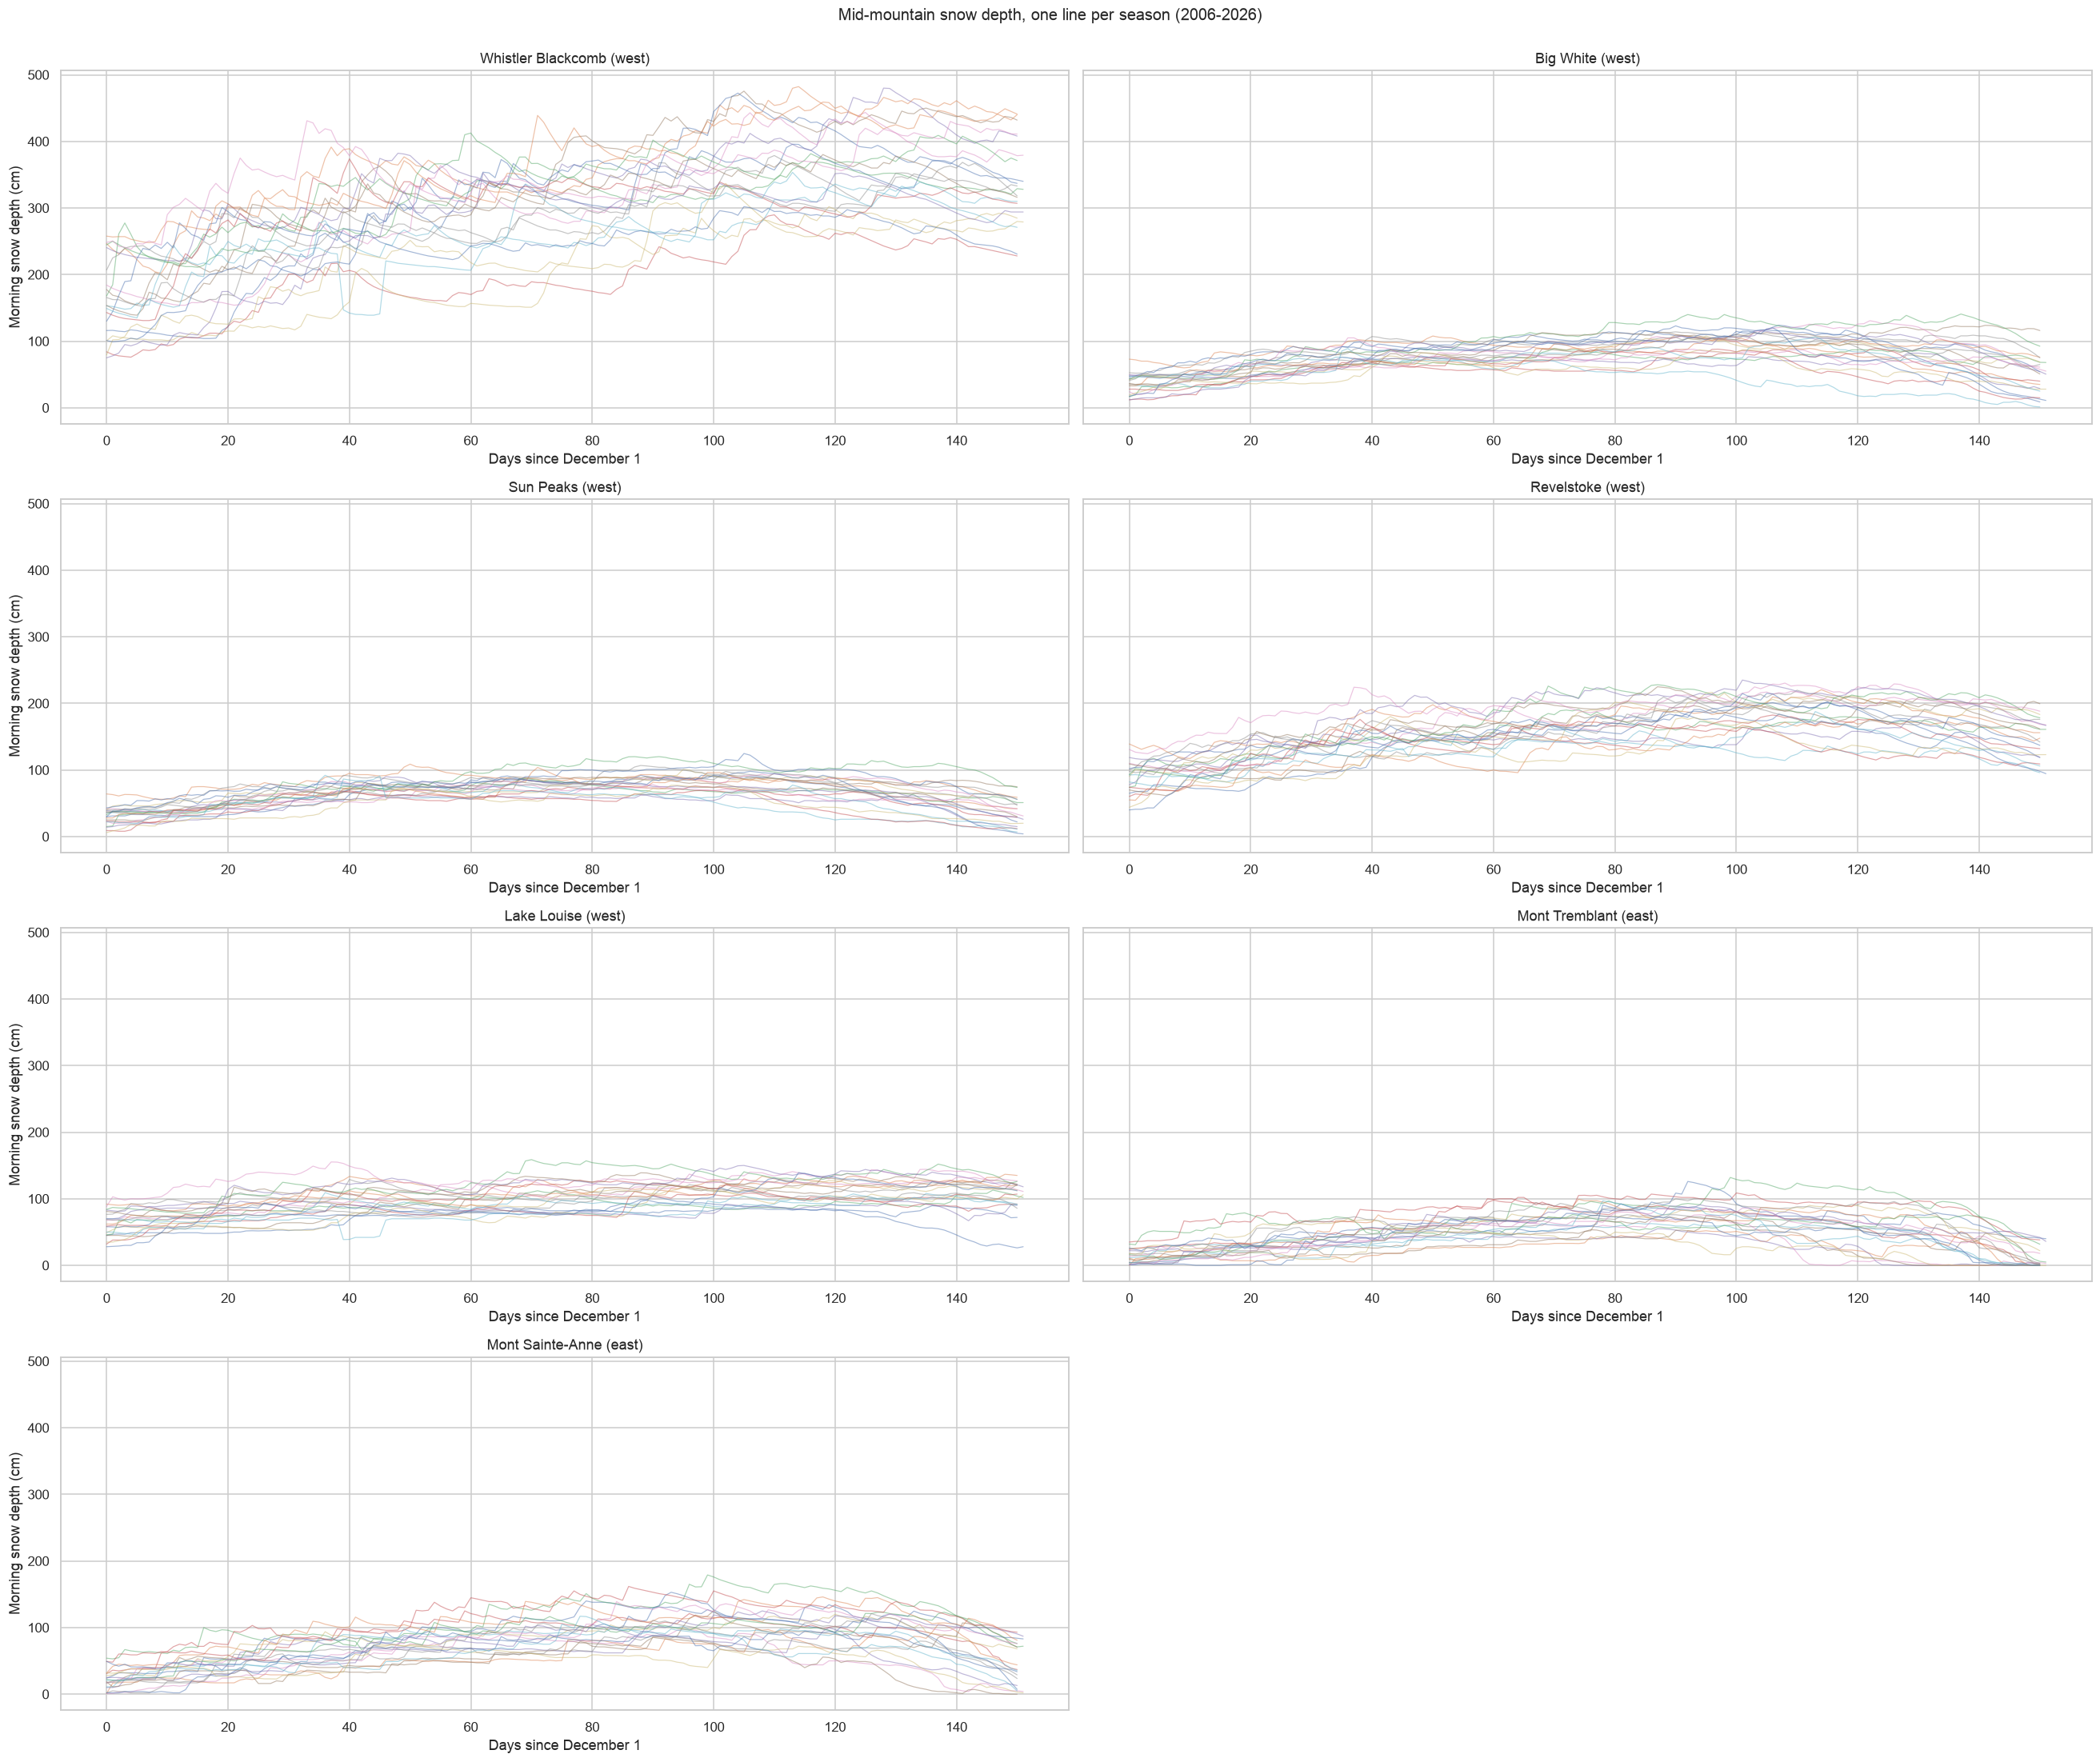

In [36]:
# Snow depth across the season
resorts = list(RESORTS)
fig, axes = plt.subplots(4, 2, figsize=(24,20), sharey=True)
for ax, name in zip(axes.flat, resorts):
    for s, gs in mid[mid["resort"] == name].groupby("season"):
        ax.plot(gs["day_of_season"], gs["snow_depth_mean_am"], lw=0.8, alpha=0.5)
    ax.set_title(f"{name} ({REGION[name]})")
    ax.set_xlabel("Days since December 1")
axes.flat[-1].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Morning snow depth (cm)")
fig.suptitle("Mid-mountain snow depth, one line per season (2006-2026)", y=1)
fig.tight_layout()
plt.show()

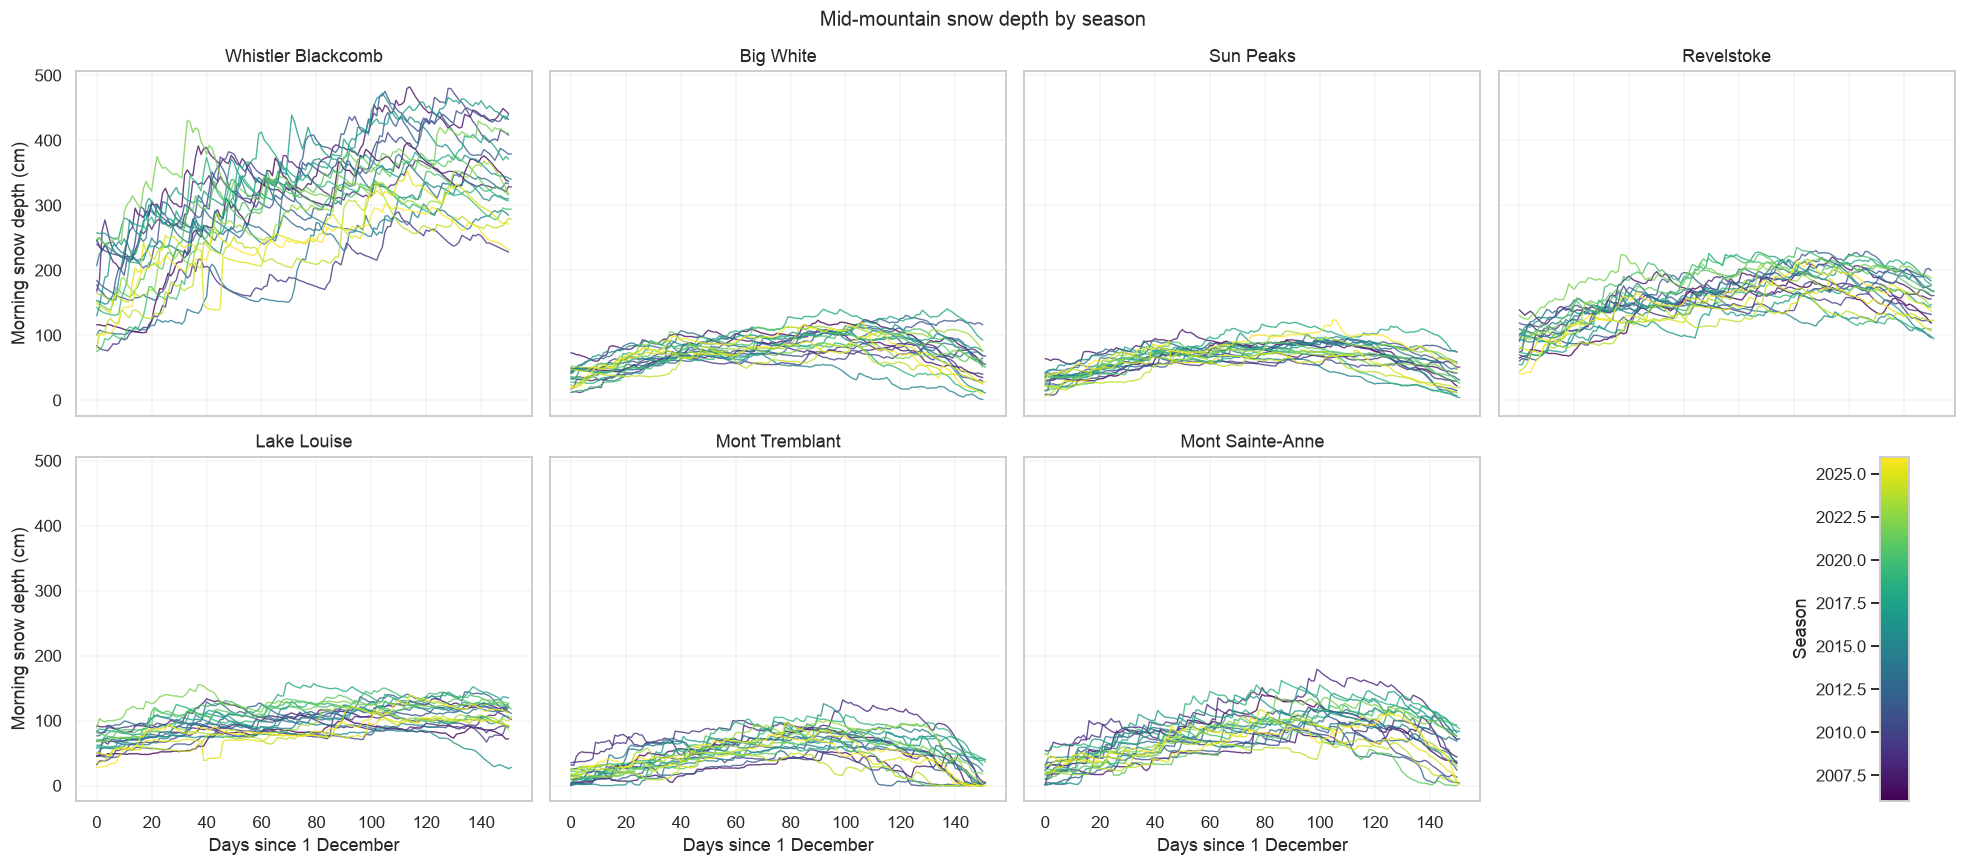

In [37]:
# Checking year to year variation: snow depth
norm, cmap = colors.Normalize(2006, 2026), cm.viridis

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, resorts):
    for s, gs in mid[mid["resort"] == name].groupby("season"):
        ax.plot(gs["day_of_season"], gs["snow_depth_mean_am"], lw=0.9, alpha=0.8, color=cmap(norm(s)))
    ax.set_title(name); ax.grid(alpha=0.2)
axes.flat[-1].set_visible(False)
for ax in axes[1, :3]: ax.set_xlabel("Days since 1 December")
for ax in axes[:, 0]: ax.set_ylabel("Morning snow depth (cm)")
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=axes.flat[-1], fraction=0.9, aspect=12, location="left").set_label("Season")
fig.suptitle("Mid-mountain snow depth by season")
fig.tight_layout()
plt.show()

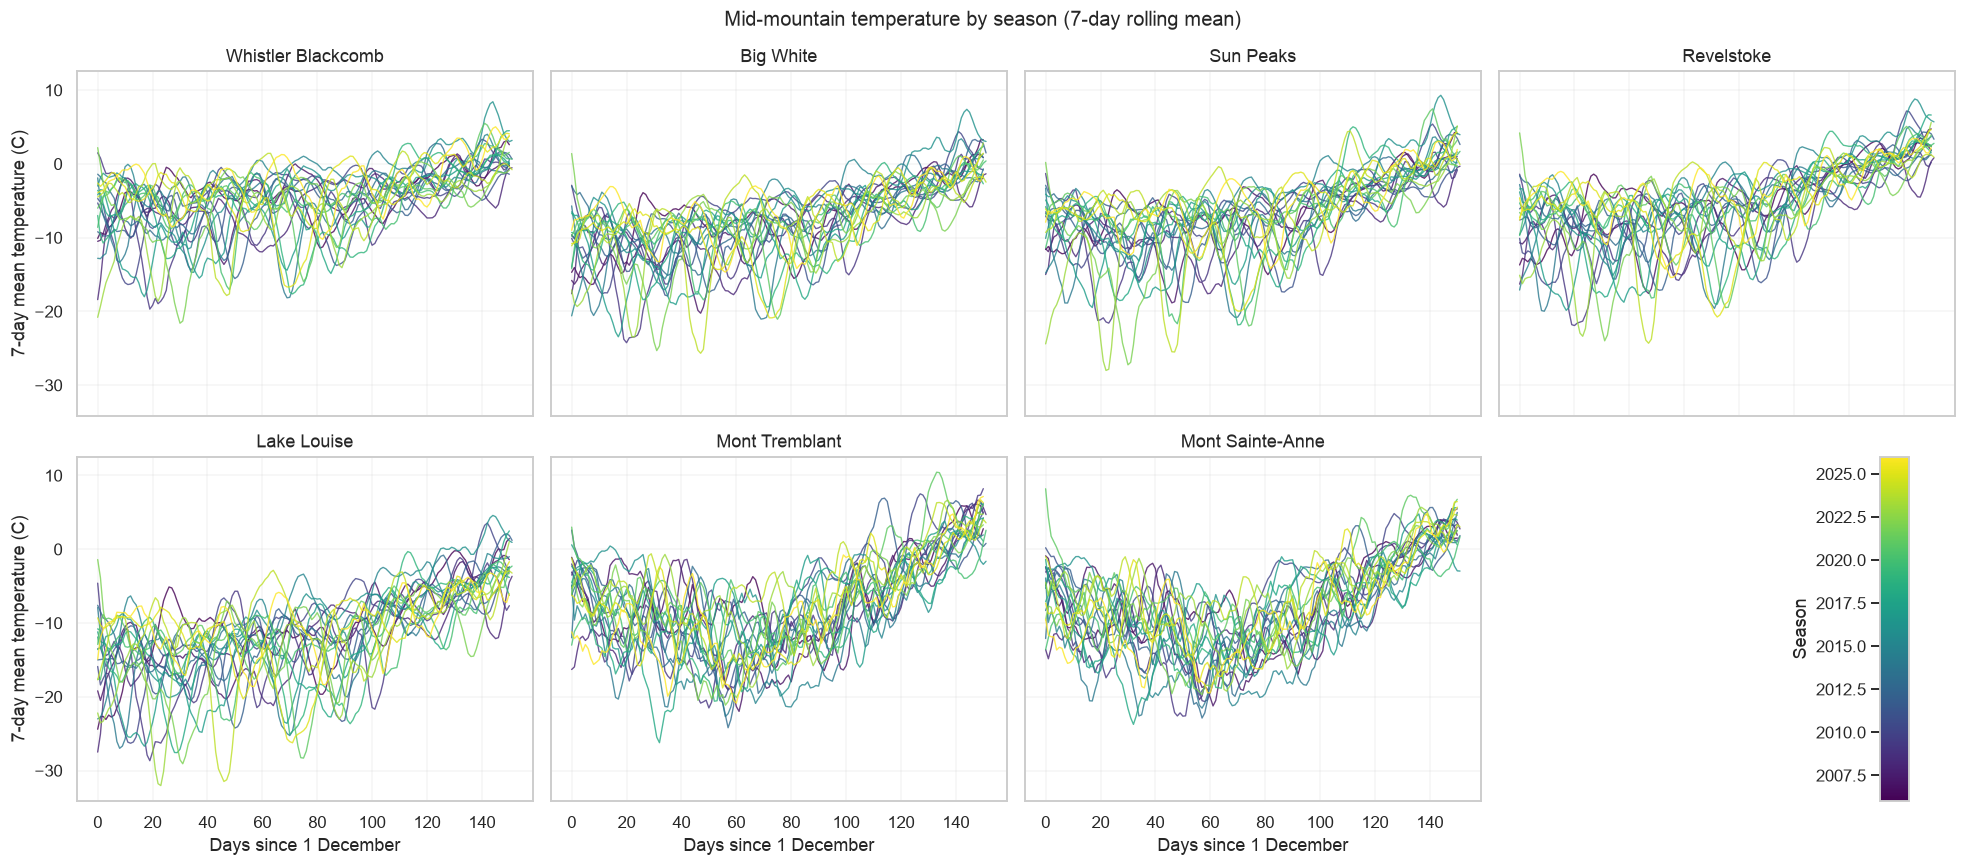

In [38]:
# Checking year to year variation: temperature
norm, cmap = colors.Normalize(2006, 2026), cm.viridis

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, resorts):
    for s, gs in mid[mid["resort"] == name].groupby("season"):
        ax.plot(gs["day_of_season"], gs["temp_7d"], lw=0.9, alpha=0.8, color=cmap(norm(s)))
    ax.set_title(name); ax.grid(alpha=0.2)
axes.flat[-1].set_visible(False)
for ax in axes[1, :3]: ax.set_xlabel("Days since 1 December")
for ax in axes[:, 0]: ax.set_ylabel("7-day mean temperature (C)")
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=axes.flat[-1], fraction=0.9, aspect=12, location="left").set_label("Season")
fig.suptitle("Mid-mountain temperature by season (7-day rolling mean)")
fig.tight_layout()
plt.show()

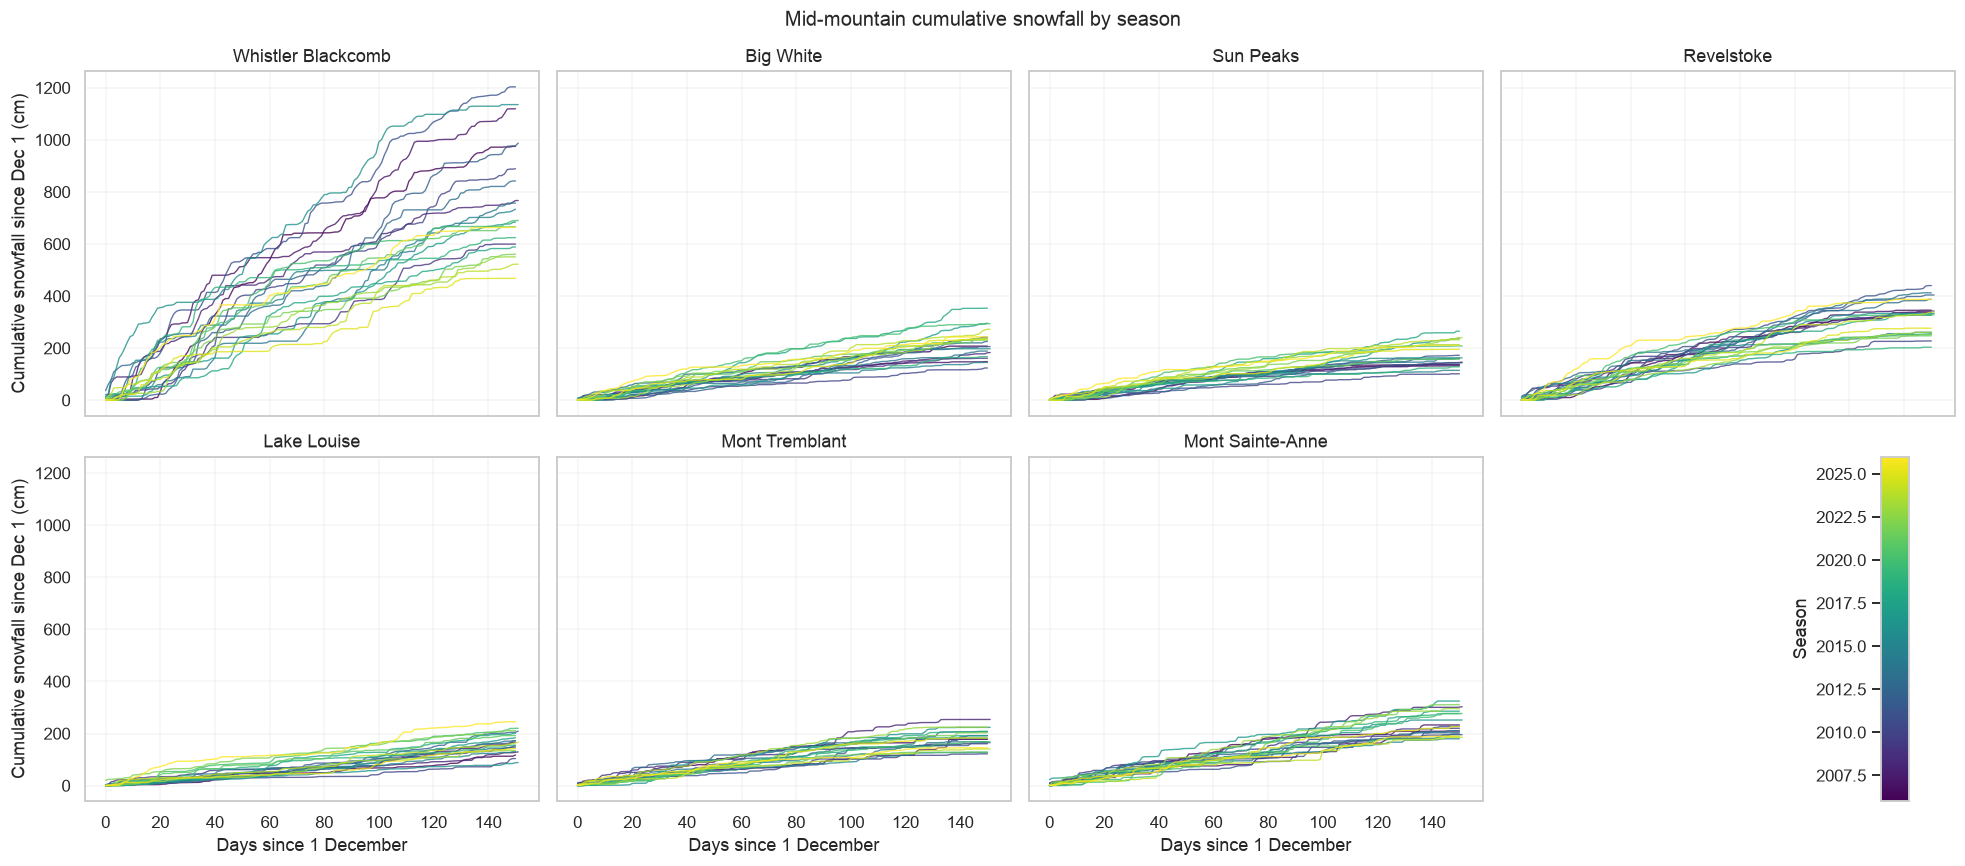

In [39]:
# Checking year to year variation: cumulative snowfall
norm, cmap = colors.Normalize(2006, 2026), cm.viridis

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, resorts):
    for s, gs in mid[mid["resort"] == name].groupby("season"):
        ax.plot(gs["day_of_season"], gs["cum_snowfall"], lw=0.9, alpha=0.8, color=cmap(norm(s)))
    ax.set_title(name); ax.grid(alpha=0.2)
axes.flat[-1].set_visible(False)
for ax in axes[1, :3]: ax.set_xlabel("Days since 1 December")
for ax in axes[:, 0]: ax.set_ylabel("Cumulative snowfall since Dec 1 (cm)")
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=axes.flat[-1], fraction=0.9, aspect=12, location="left").set_label("Season")
fig.suptitle("Mid-mountain cumulative snowfall by season")
fig.tight_layout()
plt.show()

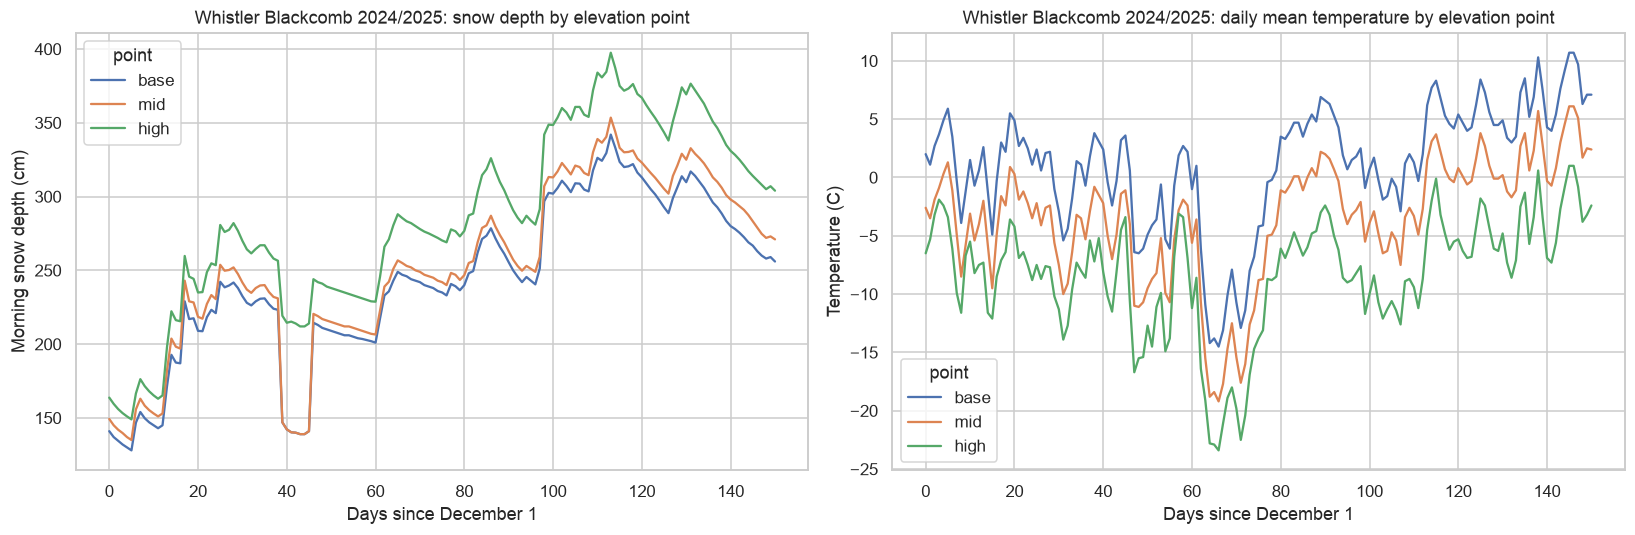

In [40]:
# Base vs mid vs high for one resort in one season
name, s = "Whistler Blackcomb", 2025
fig, axes = plt.subplots(1, 2, figsize=(15,5))
for point in POINTS:
    g = ski[(ski["resort"] == name) & (ski["point"] == point) & (ski["season"] == s)]
    axes[0].plot(g["day_of_season"], g["snow_depth_mean_am"], label=point)
    axes[1].plot(g["day_of_season"], g["temperature_2m_mean"], label=point)
axes[0].set_title(f"{name} {s-1}/{s}: snow depth by elevation point")
axes[0].set_ylabel("Morning snow depth (cm)")
axes[1].set_title(f"{name} {s-1}/{s}: daily mean temperature by elevation point")
axes[1].set_ylabel("Temperature (C)")
for ax in axes:
    ax.set_xlabel("Days since December 1")
    ax.legend(title="point")
fig.tight_layout()
plt.show()

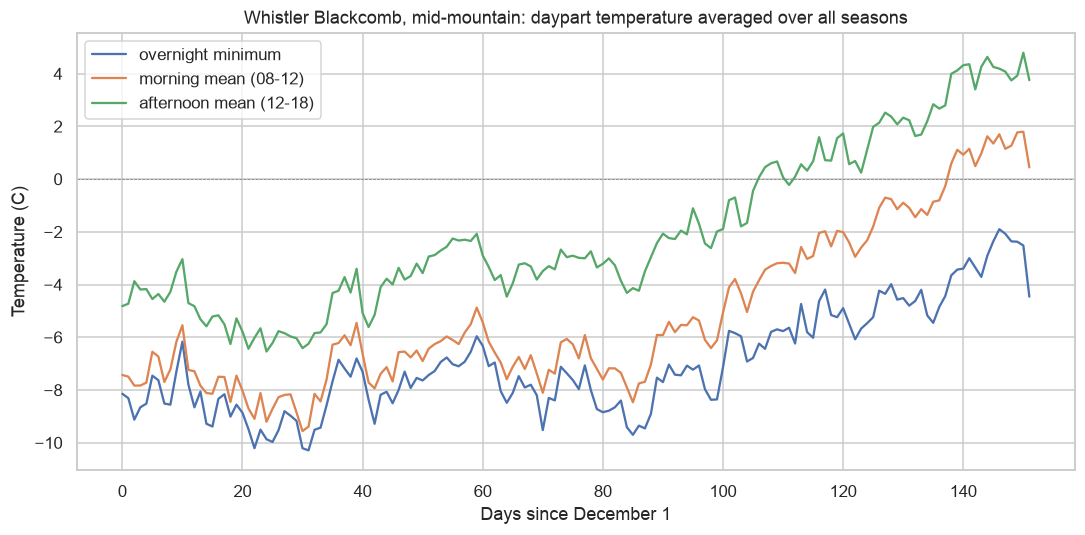

In [41]:
# within-day variation: am/pm/night temperature, averaged by day of season
name = "Whistler Blackcomb"
g = mid[mid["resort"] == name].groupby("day_of_season")[["temp_min_night", "temp_mean_am", "temp_mean_pm"]].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(g.index, g["temp_min_night"], label="overnight minimum")
ax.plot(g.index, g["temp_mean_am"], label="morning mean (08-12)")
ax.plot(g.index, g["temp_mean_pm"], label="afternoon mean (12-18)")
ax.axhline(0, color="grey", linewidth=0.5, linestyle="--")
ax.set_title(f"{name}, mid-mountain: daypart temperature averaged over all seasons")
ax.set_xlabel("Days since December 1")
ax.set_ylabel("Temperature (C)")
ax.legend()
fig.tight_layout()
plt.show()

## 3.6 Information leakage

Task: on date t, using only rows with date <= t, predict conditions on date t+30 at the same resort and point.

- Features are functions of past rows only: lags, rolling means, day-of-season, resort/point/region indicators. Daypart columns of day t are legitimate features (the night before t is over by the time we predict). Daypart columns of day t+30 are targets.
- **Historical-average baseline**: for a target on day-of-season *d* at a resort-point, the mean of the target on day *d* across training seasons only. Computed inside the training folds, never on the full table. With dayparts, the baseline is daypart-specific in the same way. 
- **Split by season**, with test seasons later than training seasons. Every fitted step (scaler, imputer, baseline averages, mode) fits on training seasons only.
- A score from one split is not a result; validation seasons are for model selection, and the test seasons are scored once at the end.

In [42]:
TRAIN_SEASONS = list(range(2006, 2021))
VAL_SEASONS = [2021, 2022, 2023]
TEST_SEASONS = [2024, 2025, 2026]
assert max(TRAIN_SEASONS) < min(VAL_SEASONS) < min(TEST_SEASONS)

In [43]:
ski["split"] = np.select(
    [ski["season"].isin(TRAIN_SEASONS), ski["season"].isin(VAL_SEASONS), ski["season"].isin(TEST_SEASONS)],
    ["train", "val", "test"], default="unused"
)
ski.groupby("split")["season"].agg(n_rows="size", seasons="nunique")

,n_rows,seasons
split,,
test,9534,3
train,47649,15
val,9513,3


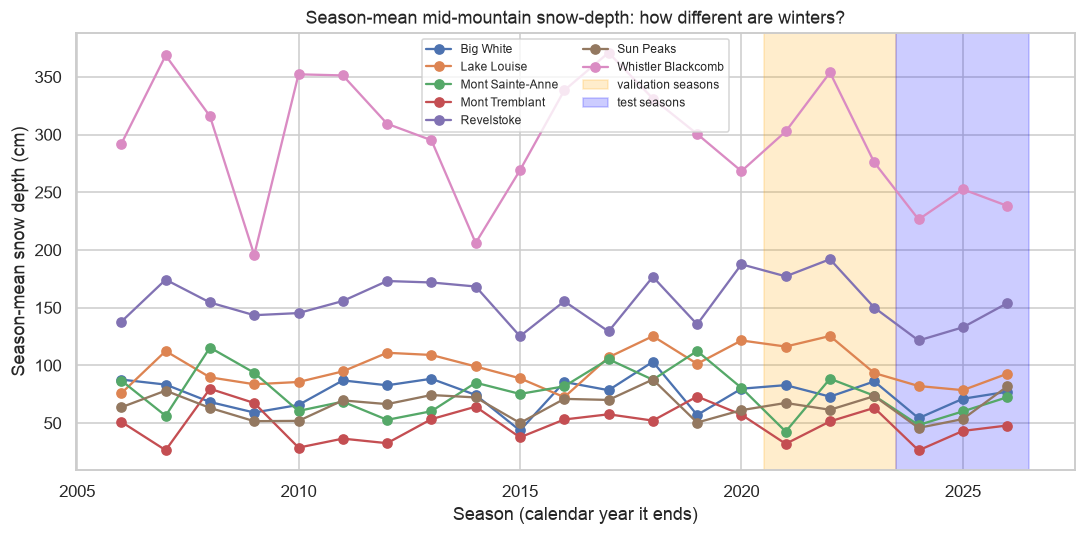

In [44]:
# Season to season variability
piv = mid.groupby(["season", "resort"])["snow_depth_mean_am"].mean().unstack()
fig, ax = plt.subplots(figsize=(10,5))
piv.plot(marker="o", ax=ax)
ax.axvspan(min(VAL_SEASONS) - 0.5, max(VAL_SEASONS) + 0.5, color="orange", alpha=0.2, label="validation seasons")
ax.axvspan(min(TEST_SEASONS) - 0.5, max(TEST_SEASONS) + 0.5, color="blue", alpha=0.2, label="test seasons")
ax.set_title("Season-mean mid-mountain snow-depth: how different are winters?")
ax.set_xlabel("Season (calendar year it ends)")
ax.set_ylabel("Season-mean snow depth (cm)")
ax.legend(fontsize=8,ncol=2)
fig.tight_layout()
plt.show()

In [45]:
# Check if the test winters different from the training winters
season_stats = (mid.groupby(["resort", "season"])
                   .agg(temp=("temperature_2m_mean", "mean"),
                        depth=("snow_depth_mean_am", "mean"),
                        snowfall=("snowfall_sum", "sum"),
                        rain=("rain_sum", "sum"))
                   .reset_index())

is_test = season_stats["season"].isin(TEST_SEASONS)
rows = []
for name, g in season_stats.groupby("resort"):
    tr, te = g[~g["season"].isin(TEST_SEASONS)], g[g["season"].isin(TEST_SEASONS)]
    for var in ["temp", "depth", "snowfall", "rain"]:
        slope = np.polyfit(g["season"], g[var], 1)[0] # linear trend
        rows.append({"resort": name, "variable": var,
                     "trend_per_decade": round(slope * 10, 1),
                     "test_minus_train_mean": round(te[var].mean() - tr[var].mean(), 1),
                     "train_sd": round(tr[var].std(), 1)})
drift = pd.DataFrame(rows)
drift["test_shift_in_sd"] = (drift["test_minus_train_mean"] / drift["train_sd"]).round(1)
drift.pivot(index="resort", columns="variable",
            values=["test_minus_train_mean", "test_shift_in_sd", "trend_per_decade"])

test_minus_train_mean                      test_shift_in_sd                    trend_per_decade                    
variable                           depth   rain snowfall temp            depth rain snowfall temp            depth  rain snowfall temp
resort                                                                                                                                
Big White                           -9.5   15.4     36.2  0.5             -0.7  0.7      0.6  0.4             -1.7  -2.9     47.2  0.1
Lake Louise                        -16.2   -1.0     24.2  0.7             -1.0 -0.4      0.6  0.5              4.0  -0.6     28.3 -0.3
Mont Sainte-Anne                   -19.0   45.2    -43.4  0.7             -0.9  1.2     -0.9  0.5             -5.8  22.0      8.5  0.6
Mont Tremblant                     -11.8   40.8    -26.3  0.7             -0.8  0.7     -0.7  0.4             -0.9  53.9     -6.1  0.4
Revelstoke                         -22.4   83.5     17.6  0.8             -1.1  2.1      0.3  0.7             -0.9  29.8    -32.2  0.4
Sun Peaks                           -5.4   15.0     48.5  1.2             -0.5  0.8      1.1  1.0             -0.3   3.7     49.8  0.4
Whistler Blackcomb                 -66.3  105.3   -247.1  1.3             -1.3  1.8     -1.2  1.1            -22.9  26.1   -235.7  0.3

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**Differences between training and test winters.** The test seasons are warmer than the 2006–2023 mean at every resort, by about 1 °C, and have thinner snowpacks at most resorts (Whistler by about 60 cm). 

What we'll be measuring would also inevitably include climate drift. So, the consequences for the plan: test results are reported relative to the historical-average baseline and after the model selection on validation seasons, the chosen model and the baseline averages are refit on all development (training + validation) seasons before the test seasons are scored once. A `season` variable probably needs to be included so the models can learn the trend.

## 3.7 Draft skiing-condition index (candidate target)

A transparent 0-100 index for the ski day (am + pm). Each component is clipped to [0, 1] and weighted. The weights are a **design choice** to be varied in Milestone 4. This is a calculated index, not observed skiing quality.

In [46]:
# the weight should be tested and adjusted (everything for that matter can be adjusted)
# snow depth = 100 cm+ -> full score
# fresh snow 15 cm overnight -> full score
# temperature best near -4 C
# any daytime rain is bad
def ski_index(df, w_depth=0.35, w_fresh=0.20, w_sun=0.15, w_temp=0.15, w_wind=0.10, w_rain=0.05):
    depth = (df["snow_depth_mean_am"]/100).clip(0,1)
    fresh = (df["snowfall_sum_night"]/15).clip(0,1)
    sun = (df["sunshine_hours"]/df["daylight_hours"]).clip(0,1)
    day_t = (df["temp_mean_am"] + df["temp_mean_pm"]) / 2
    temp = 1 - ((day_t + 4).abs().clip(0,16) / 16)
    wind = 1 - ((df["gust_max_am"].combine(df["gust_max_pm"], max) - 50).clip(0, 50) / 50)
    rain = 1 - ((df["rain_sum_am"] + df["rain_sum_pm"]).clip(0,5)/5)
    return 100 * (w_depth*depth + w_fresh*fresh + w_sun*sun + w_temp*temp + w_wind*wind + w_rain*rain)


In [47]:
ski["ski_index"] = ski_index(ski)
ski.groupby(["resort","point"])["ski_index"].describe().round(2)

count   mean    std    min    25%    50%    75%    max
resort             point                                                         
Big White          base   3176.0  61.80  10.36  30.47  55.01  62.63  69.54  88.55
                   high   3176.0  62.21  10.34  27.40  54.88  63.07  70.24  86.99
                   mid    3176.0  61.62  10.50  28.68  54.47  62.31  69.49  88.70
Lake Louise        base   3176.0  66.75   8.31  31.06  61.52  68.17  73.05  86.14
                   high   3176.0  63.71   8.87  28.60  57.93  64.64  70.18  87.17
                   mid    3176.0  65.55   8.73  31.13  59.91  66.68  72.04  89.70
Mont Sainte-Anne   base   3176.0  58.00  12.60  12.94  49.40  59.23  67.93  90.44
                   high   3176.0  57.96  12.01  17.82  48.92  59.03  67.12  85.04
                   mid    3176.0  58.40  12.04  15.95  49.61  59.69  67.80  86.53
Mont Tremblant     base   3176.0  49.44  12.52   7.28  40.81  49.83  58.56  92.12
                   high   3176.0  50.04  12.01  10.21  41.11  49.95  59.08  88.30
                   mid    3176.0  49.25  12.21   8.63  40.75  49.50  58.00  90.16
Revelstoke         base   3176.0  66.44   7.58  37.27  61.63  66.85  72.13  88.34
                   high   3176.0  68.58   7.61  36.37  63.71  68.82  74.52  89.49
                   mid    3176.0  69.88   6.87  41.62  65.21  70.20  74.93  91.82
Sun Peaks          base   3176.0  57.18  10.32  23.29  50.54  57.90  64.84  82.98
                   high   3176.0  57.18   9.85  26.06  50.31  58.07  64.34  86.29
                   mid    3176.0  58.02   9.89  27.17  51.20  58.66  65.26  83.47
Whistler Blackcomb base   3176.0  66.08   8.86  38.49  59.61  67.15  72.69  94.26
                   high   3176.0  71.11   7.67  46.57  65.31  71.45  76.51  97.69
                   mid    3176.0  72.03   7.42  50.11  66.54  72.43  76.81  98.31

In [48]:
ski = ski.drop(columns=["season_start"])
ski.to_csv("data/ski_season_clean.csv", index=False)
print("Cleaned table saved:", ski.shape, "-> %.1f MB" % (os.path.getsize("data/ski_season_clean.csv") / 1e6))

Cleaned table saved: (66696, 102) -> 53.6 MB


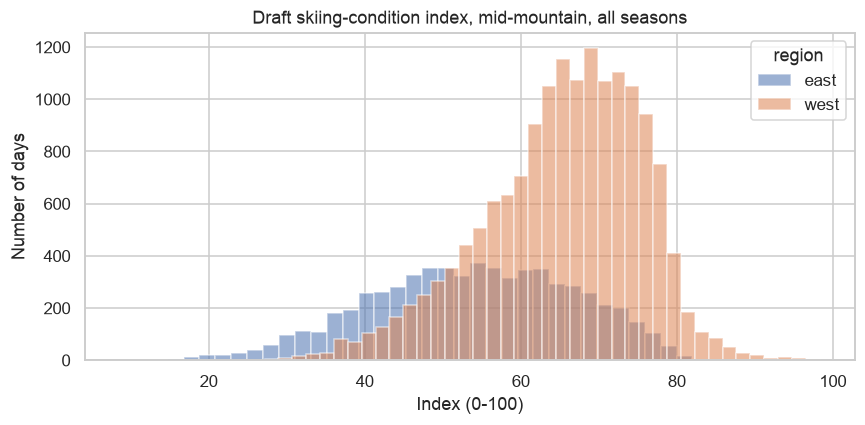

In [49]:
mid = ski[ski["point"]=="mid"]
# Distribution of the candidate target by region
fig, ax = plt.subplots(figsize=(8,4))
for region, g in mid.groupby("region"):
    ax.hist(g["ski_index"], bins=40, alpha=0.55, label=region)
ax.set_title("Draft skiing-condition index, mid-mountain, all seasons")
ax.set_xlabel("Index (0-100)")
ax.set_ylabel("Number of days")
ax.legend(title="region")
fig.tight_layout()
plt.show()

In [51]:
#30-day autocorrelation
targets = ["snow_depth_mean_am", "temperature_2m_mean", "temp_mean_am", "temp_mean_pm", "sunshine_hours",
           "wind_speed_10m_max", "wind_gusts_10m_max", "rain_sum", "ski_index"]
rows = []
for name, g in mid.groupby("resort"):
    g = g.set_index("date")
    for t in targets:
        rows.append({"resort": name, "variable": t, "lag30_autocorr": round(g[t].autocorr(lag=30),3)})
pd.DataFrame(rows).pivot(index="variable", columns="resort", values="lag30_autocorr")

resort,Big White,Lake Louise,Mont Sainte-Anne,Mont Tremblant,Revelstoke,Sun Peaks,Whistler Blackcomb
variable,,,,,,,
rain_sum,-0.014,-0.006,-0.002,0.033,0.023,0.013,0.012
ski_index,0.206,0.125,0.212,0.254,0.036,0.204,0.035
snow_depth_mean_am,0.301,0.438,0.401,0.397,0.333,0.312,0.335
sunshine_hours,0.061,0.084,0.019,0.037,0.058,0.058,0.015
temp_mean_am,0.062,0.004,0.106,0.107,0.070,0.043,0.006
temp_mean_pm,0.064,0.038,0.122,0.131,0.069,0.054,0.009
temperature_2m_mean,0.053,0.010,0.111,0.117,0.060,0.031,0.000
wind_gusts_10m_max,0.031,0.088,0.072,0.052,0.060,0.150,0.053
wind_speed_10m_max,0.030,0.074,0.043,0.029,0.139,0.076,0.060


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What the autocorrelation tells us.** At a 30-day lag, snow depth still carries memory (autocorrelation 0.30-0.44 across resorts, with the ski index at 0.04-0.25), while temperature, sunshine, rain, and wind are essentially uncorrelated with themselves a month later. In short, the snowpack in 30 days depends on the snowpack today, but the weather on that day does not. That's why we need to predict ski-condition index, where today's state is informative, rather than the raw weather elements.

## 3.8 Data Quality Findings and Implications

Our data examination revealed several findings relevant to the revised project.

| Finding | Implication |
|---|---|
| The initial daily dataset contains no missing values. | No general imputation is currently needed. |
| Some resorts have identical snow-depth values across elevations. | Elevation-specific snow-depth predictions require caution. |
| Recent seasons differ from earlier seasons in temperature and snow depth. | Chronological evaluation is important for assessing generalization. |
| Snow depth shows stronger persistence than most other weather variables in the preliminary lag analysis. | Historical snow depth may be a useful predictor. |
| The skiing condition index is derived from weather variables. | Predictions represent a weather-based proxy, not observed skiing quality. |

These findings support a 30-day-ahead prediction task while identifying limitations that should be considered during model development and evaluation.
